# FloodShift 11 — FINAL Research Closure (Direct 04H-CAL)

This is the **final non-dashboard research notebook**.

It directly reconstructs the exact accepted **TerraMind-RIFT → 04H hierarchical residual → CAL** detector from the frozen `FloodShift_04H_best_mIoU.pt` checkpoint. No separate 04E checkpoint or custom adapter is required because the 04H checkpoint contains the complete `base.*` + `head.*` state dictionary.

## Attached inputs already confirmed

- `FloodShift_04H_best_mIoU.pt`
- `FloodShift_04H_CAL_config.pt`
- `FloodShift_05_uncertainty_config.pt`
- `FloodShift_05_protocol_record.json`
- Notebook 01 output: raw S1/S2/flood/JRC data + immutable split manifests
- Notebook 03 output: frozen preprocessing manifest, optical normalization, SAR statistics, all P(clear) maps
- Notebook 04H output: exact source architecture, used here verbatim in structure

## Final sequence

**No training occurs.**

1. discover and hash frozen artifacts;
2. load exact frozen preprocessing;
3. reconstruct the exact 04H architecture;
4. load the complete 04H checkpoint;
5. apply CAL type-logit bias `-0.15`;
6. reproduce the accepted validation result;
7. freeze the final protocol;
8. unlock Pakistan + Spain exactly once;
9. run final segmentation / calibration / uncertainty / attribution evaluation;
10. generate independent verifier audits;
11. create country-wise generalization results + bootstrap CIs;
12. create paper tables/figures;
13. export a final reproducibility archive.

> **Critical rule:** if the validation reproduction fails, the test remains locked.

In [16]:
# ============================================================
# P21-C00 — ENVIRONMENT + FINAL-RUN SETTINGS
# ============================================================
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")

import sys, gc, re, json, time, math, random, hashlib, zipfile, shutil, subprocess
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import rasterio
from rasterio.windows import Window
from scipy import ndimage
from sklearn.metrics import roc_auc_score

# TerraTorch: use the current Kaggle environment if already installed.
# If missing, install it once. The validation-reproduction gate below
# prevents us from opening the test with an incompatible implementation.
try:
    import terratorch
except ImportError:
    print("TerraTorch not found; installing terratorch...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "terratorch"])
    import terratorch

from terratorch.registry import BACKBONE_REGISTRY

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
AMP_ENABLED = torch.cuda.is_available()
torch.backends.cudnn.benchmark = True

INPUT_ROOT = Path("/kaggle/input")
OUTPUT_ROOT = Path("/kaggle/working/FloodShift_11_Final_Research_Closure")
TABLE_ROOT = OUTPUT_ROOT / "tables"
FIG_ROOT = OUTPUT_ROOT / "figures"
PACKET_ROOT = OUTPUT_ROOT / "test_packets"
PROTOCOL_ROOT = OUTPUT_ROOT / "protocol"
CACHE_ROOT = OUTPUT_ROOT / "prediction_cache"

for p in [OUTPUT_ROOT, TABLE_ROOT, FIG_ROOT, PACKET_ROOT, PROTOCOL_ROOT, CACHE_ROOT]:
    p.mkdir(parents=True, exist_ok=True)

# Keep locked until protocol freeze cell explicitly tells you to change it.
CONFIRM_ONE_TIME_GEOGRAPHIC_TEST = "UNLOCK_PAKISTAN_SPAIN_ONCE"
# The misregistration diagnostic is useful but computationally expensive.
# It is validation-only and never changes the final model.
RUN_VALIDATION_MISREGISTRATION = False

EXPECTED_04H_SHA = "ef3341a7579f1316c80290dcd2a8f972c0adbf7e03e7a8c6bc239f30c4b47e53"
EXPECTED_04E_SOURCE_SHA = "6ab8ad8b41aa64b4ceee403539d8554a14f61cab235a0f0841ef13f77e390822"

print("=" * 112)
print("P21-C00 — FINAL RESEARCH CLOSURE")
print("=" * 112)
print("Python     :", sys.version.split()[0])
print("PyTorch    :", torch.__version__)
print("TerraTorch :", getattr(terratorch, "__version__", "unknown"))
print("Device     :", DEVICE)
print("Test state : LOCKED_NOT_EVALUATED")
print("Training   : DISABLED")
print("P21-C00 COMPLETE ✅")

P21-C00 — FINAL RESEARCH CLOSURE
Python     : 3.12.13
PyTorch    : 2.10.0+cu128
TerraTorch : unknown
Device     : cuda:0
Test state : LOCKED_NOT_EVALUATED
Training   : DISABLED
P21-C00 COMPLETE ✅


In [4]:
# ============================================================
# P21-C01 — DISCOVER EXACT FROZEN INPUTS
# ============================================================

def find_exact(filename, required=True):
    matches = sorted(
        INPUT_ROOT.rglob(filename),
        key=lambda p: (len(str(p)), str(p)),
    )
    if not matches:
        if required:
            raise FileNotFoundError(f"Could not find {filename} under /kaggle/input")
        return None
    return matches[0]

def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

CKPT_04H = find_exact("FloodShift_04H_best_mIoU.pt")
CAL_PATH = find_exact("FloodShift_04H_CAL_config.pt")
UNC_PATH = find_exact("FloodShift_05_uncertainty_config.pt")
PROTOCOL05_PATH = find_exact("FloodShift_05_protocol_record.json")

FINAL_MANIFEST_PATH = find_exact("floodshift_preprocessing_manifest_v1.csv")
GLOBAL_LOCK_PATH = find_exact("floodshift_preprocessing_GLOBAL_LOCK_v1.json")
OPTICAL_NORM_PATH = find_exact("optical_10band_train_normalization_exact.csv")
SAR_SCENE_STATS_PATH = find_exact("train_raw_sar_scene_statistics.csv")

sha04h = sha256_file(CKPT_04H)
assert sha04h == EXPECTED_04H_SHA, (
    f"Wrong 04H checkpoint.\nExpected {EXPECTED_04H_SHA}\nFound {sha04h}"
)

with open(GLOBAL_LOCK_PATH, "r") as f:
    preprocessing_lock = json.load(f)

assert preprocessing_lock["status"] == "PERMANENTLY_FROZEN"
assert preprocessing_lock["preprocessing_development_closed"] is True

cal_cfg = torch.load(CAL_PATH, map_location="cpu", weights_only=False)
unc_cfg = torch.load(UNC_PATH, map_location="cpu", weights_only=False)
with open(PROTOCOL05_PATH, "r") as f:
    protocol05 = json.load(f)

assert cal_cfg["source_04h_checkpoint_sha256"] == EXPECTED_04H_SHA
assert unc_cfg["source_04h_sha256"] == EXPECTED_04H_SHA
assert abs(float(cal_cfg["type_bias"]) - (-0.15)) < 1e-12
assert abs(float(unc_cfg["temperature"]) - 0.989592432975769) < 1e-12
assert unc_cfg["test_status"] == "LOCKED_NOT_EVALUATED"
assert protocol05["test_status"] == "LOCKED_NOT_EVALUATED"

TYPE_BIAS = float(cal_cfg["type_bias"])
TEMPERATURE = float(unc_cfg["temperature"])
REVIEW10_THRESHOLD = float(unc_cfg["entropy_threshold_review_10"])
REVIEW20_THRESHOLD = float(unc_cfg["entropy_threshold_review_20"])

print("=" * 112)
print("P21-C01 — FROZEN INPUTS VERIFIED")
print("=" * 112)
print("04H checkpoint :", CKPT_04H)
print("04H SHA256     :", sha04h)
print("CAL type bias  :", TYPE_BIAS)
print("Temperature    :", TEMPERATURE)
print("Review10 thr   :", REVIEW10_THRESHOLD)
print("Review20 thr   :", REVIEW20_THRESHOLD)
print("Preproc lock   :", preprocessing_lock["status"])
print("Test           : LOCKED_NOT_EVALUATED")
print("P21-C01 COMPLETE ✅")

P21-C01 — FROZEN INPUTS VERIFIED
04H checkpoint : /kaggle/input/datasets/himavarshini2108/floodshift-04hh-best-miou-pt/FloodShift_04H_best_mIoU.pt
04H SHA256     : ef3341a7579f1316c80290dcd2a8f972c0adbf7e03e7a8c6bc239f30c4b47e53
CAL type bias  : -0.15
Temperature    : 0.989592432975769
Review10 thr   : 0.1218614846467972
Review20 thr   : 0.04920305460691452
Preproc lock   : PERMANENTLY_FROZEN
Test           : LOCKED_NOT_EVALUATED
P21-C01 COMPLETE ✅


In [5]:
# ============================================================
# P21-C02 — FROZEN MANIFEST + TRAIN-ONLY NORMALIZATION
# Exact source from the accepted 04H notebook.
# ============================================================

manifest = pd.read_csv(FINAL_MANIFEST_PATH)

assert len(manifest) == 440
assert manifest["scene_id"].nunique() == 440

train_df = manifest[manifest["split"] == "train"].copy().reset_index(drop=True)
val_df = manifest[manifest["split"] == "validation"].copy().reset_index(drop=True)
test_df = manifest[manifest["split"] == "test"].copy().reset_index(drop=True)

assert len(train_df) == 314
assert len(val_df) == 68
assert len(test_df) == 58

# Frozen geographic split must be Pakistan + Spain only.
test_regions = sorted(test_df["region"].astype(str).unique().tolist())
assert test_regions == ["Pakistan", "Spain"], test_regions
assert (test_df["region"] == "Pakistan").sum() == 28
assert (test_df["region"] == "Spain").sum() == 30

optical_norm = pd.read_csv(OPTICAL_NORM_PATH)
OPTICAL_BANDS = optical_norm["band_name"].tolist()
EXPECTED_OPTICAL_BANDS = ["B2","B3","B4","B5","B6","B7","B8","B8A","B11","B12"]
assert OPTICAL_BANDS == EXPECTED_OPTICAL_BANDS

OPTICAL_MEAN = optical_norm["mean"].to_numpy(np.float32)
OPTICAL_STD = optical_norm["std"].to_numpy(np.float32)

# Original S2 source order:
# B1 B2 B3 B4 B5 B6 B7 B8 B8A B9 B10 B11 B12
OPTICAL_SOURCE_INDICES = np.array([1,2,3,4,5,6,7,8,11,12], dtype=np.int64)

sar_stats = pd.read_csv(SAR_SCENE_STATS_PATH)
assert len(sar_stats) == 314
n_all = sar_stats["valid_pixels"].to_numpy(np.float64)

def pooled_mean_std(mean_col, std_col):
    mu_all = sar_stats[mean_col].to_numpy(np.float64)
    sd_all = sar_stats[std_col].to_numpy(np.float64)
    valid = np.isfinite(mu_all) & np.isfinite(sd_all) & (n_all > 0)

    n = n_all[valid]
    mu = mu_all[valid]
    sd = sd_all[valid]

    total_n = n.sum()
    mean = np.sum(n * mu) / total_n
    second = np.sum(n * (sd**2 + mu**2)) / total_n
    var = max(second - mean**2, 0.0)
    return float(mean), float(np.sqrt(var))

VV_MEAN, VV_STD = pooled_mean_std("vv_mean_db", "vv_std_db")
VH_MEAN, VH_STD = pooled_mean_std("vh_mean_db", "vh_std_db")

SAR_MEAN = np.array([VV_MEAN, VH_MEAN], dtype=np.float32)
SAR_STD = np.array([VV_STD, VH_STD], dtype=np.float32)

assert np.isfinite(SAR_MEAN).all()
assert np.isfinite(SAR_STD).all()
assert (SAR_STD > 0).all()

print("=" * 112)
print("P21-C02 — DATA CONFIG")
print("=" * 112)
print("Train / Val / Test :", len(train_df), len(val_df), len(test_df))
print("Test regions       :", test_df["region"].value_counts().to_dict())
print("Optical bands      :", OPTICAL_BANDS)
print("SAR mean [VV,VH]   :", SAR_MEAN)
print("SAR std  [VV,VH]   :", SAR_STD)
print("P21-C02 COMPLETE ✅")

P21-C02 — DATA CONFIG
Train / Val / Test : 314 68 58
Test regions       : {'Spain': 30, 'Pakistan': 28}
Optical bands      : ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']
SAR mean [VV,VH]   : [-10.358468 -17.10712 ]
SAR std  [VV,VH]   : [4.161632  4.8134336]
P21-C02 COMPLETE ✅


In [6]:
# ============================================================
# P21-C03 — EXACT DATA/TARGET PIPELINE
# ============================================================

IGNORE_INDEX = 255
NUM_CLASSES = 3
CLASS_NAMES = ["non_flood", "permanent_water", "temporary_flood"]

TILE_SIZE = 256
TILES_PER_SCENE = 4
TILE_OFFSETS = [(0,0), (0,256), (256,0), (256,256)]

_file_cache = {}

def locate_by_saved_path(saved_path_or_name):
    filename = Path(str(saved_path_or_name)).name
    if filename in _file_cache:
        return _file_cache[filename]

    matches = sorted(
        INPUT_ROOT.rglob(filename),
        key=lambda p: (len(str(p)), str(p)),
    )
    if not matches:
        raise FileNotFoundError(f"Could not locate {filename} under /kaggle/input")
    _file_cache[filename] = matches[0]
    return matches[0]

def resolve_scene_files(row):
    return {
        "sar": locate_by_saved_path(row["sar_raw_path"]),
        "optical": locate_by_saved_path(row["optical_raw_path"]),
        "flood": locate_by_saved_path(row["flood_label_path"]),
        "jrc": locate_by_saved_path(row["jrc_water_path"]),
        "reliability": locate_by_saved_path(row["optical_reliability_path"]),
    }

def build_three_class_target(flood, jrc):
    flood = np.asarray(flood)
    jrc = np.asarray(jrc)

    target = np.full(flood.shape, IGNORE_INDEX, dtype=np.uint8)
    valid = flood != -1
    target[valid] = 0

    # Frozen project semantics.
    target[valid & (jrc == 1)] = 1
    target[valid & (jrc != 1) & (flood == 1)] = 2
    return target

def normalize_sar(sar):
    sar = sar.astype(np.float32, copy=False)
    valid = np.isfinite(sar).all(axis=0)
    out = np.zeros_like(sar, dtype=np.float32)

    for c in range(2):
        m = valid & np.isfinite(sar[c])
        out[c, m] = (sar[c, m] - SAR_MEAN[c]) / SAR_STD[c]

    return out

def normalize_optical(optical_13):
    optical_13 = optical_13.astype(np.float32, copy=False)

    valid = np.all(
        np.isfinite(optical_13) & (optical_13 != 0),
        axis=0,
    )

    reflectance = optical_13 / 10000.0
    optical_10 = reflectance[OPTICAL_SOURCE_INDICES]

    out = (
        optical_10
        - OPTICAL_MEAN[:, None, None]
    ) / OPTICAL_STD[:, None, None]

    out = out.astype(np.float32, copy=False)
    out[:, ~valid] = 0.0
    return out

def read_full_scene(row):
    paths = resolve_scene_files(row)

    with rasterio.open(paths["sar"]) as src:
        sar_raw = src.read().astype(np.float32)
        profile = src.profile.copy()

    with rasterio.open(paths["optical"]) as src:
        optical_raw = src.read().astype(np.float32)

    with rasterio.open(paths["flood"]) as src:
        flood = src.read(1)

    with rasterio.open(paths["jrc"]) as src:
        jrc = src.read(1)

    reliability = np.asarray(
        np.load(paths["reliability"], mmap_mode="r"),
        dtype=np.float32,
    )
    reliability = np.clip(reliability, 0.0, 1.0)

    sar = normalize_sar(sar_raw)
    optical = normalize_optical(optical_raw)
    target = build_three_class_target(flood, jrc)

    assert sar.shape == (2, 512, 512), (row["scene_id"], sar.shape)
    assert optical.shape == (10, 512, 512), (row["scene_id"], optical.shape)
    assert reliability.shape == (512, 512), (row["scene_id"], reliability.shape)
    assert target.shape == (512, 512), (row["scene_id"], target.shape)

    return {
        "sar": sar,
        "optical": optical,
        "reliability": reliability,
        "target": target,
        "profile": profile,
    }

print("P21-C03 — EXACT DATA/TARGET PIPELINE READY ✅")

P21-C03 — EXACT DATA/TARGET PIPELINE READY ✅


In [8]:
# ============================================================
# P21-C04 — EXACT TERRAMIND-RIFT BASE ARCHITECTURE
# Reconstructed from the accepted 04H source.
# ============================================================

TM_S2_ALL_MEAN = np.array(
    [2357.089,2137.385,2018.788,2082.986,2295.651,2854.537,3122.849,
     3040.560,3306.481,1473.847,506.070,2472.825,1838.929],
    dtype=np.float32,
)

TM_S2_ALL_STD = np.array(
    [1624.683,1675.806,1557.708,1833.702,1823.738,1733.977,1732.131,
     1679.732,1727.260,1024.687,442.165,1331.411,1160.419],
    dtype=np.float32,
)

TM_S2_SUBSET_INDICES = np.array([1,2,3,4,5,6,7,8,11,12], dtype=np.int64)
TM_S2_MEAN = TM_S2_ALL_MEAN[TM_S2_SUBSET_INDICES]
TM_S2_STD = TM_S2_ALL_STD[TM_S2_SUBSET_INDICES]

TM_S1_MEAN = np.array([-12.599, -20.293], dtype=np.float32)
TM_S1_STD = np.array([5.195, 5.890], dtype=np.float32)

TM_OPTICAL_BAND_NAMES = [
    "BLUE","GREEN","RED","RED_EDGE_1","RED_EDGE_2","RED_EDGE_3",
    "NIR_BROAD","NIR_NARROW","SWIR_1","SWIR_2",
]

TM_LAYER_INDICES = [2,5,8,11]
TM_EMBED_DIM = 768
PYRAMID_CHANNELS = [64,128,256,512]
PYRAMID_SIZES = [128,64,32,16]

def make_group_norm(channels):
    for groups in [32,16,8,4,2,1]:
        if channels % groups == 0:
            return nn.GroupNorm(groups, channels)
    raise RuntimeError("No GroupNorm divisor.")

class ConvNormAct(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels, kernel_size=kernel_size,
                padding=kernel_size//2, bias=False,
            ),
            make_group_norm(out_channels),
            nn.GELU(),
        )
    def forward(self, x):
        return self.block(x)

class SEBlock(nn.Module):
    def __init__(self, channels, reduction=8):
        super().__init__()
        hidden = max(channels // reduction, 8)
        self.fc1 = nn.Conv2d(channels, hidden, 1)
        self.fc2 = nn.Conv2d(hidden, channels, 1)
    def forward(self, x):
        w = F.adaptive_avg_pool2d(x, 1)
        w = F.gelu(self.fc1(w))
        w = torch.sigmoid(self.fc2(w))
        return x * w

class ConvNeXtRefine(nn.Module):
    def __init__(self, channels, drop=0.0):
        super().__init__()
        self.dw = nn.Conv2d(channels, channels, 7, padding=3, groups=channels)
        self.norm = make_group_norm(channels)
        self.pw1 = nn.Conv2d(channels, channels*4, 1)
        self.pw2 = nn.Conv2d(channels*4, channels, 1)
        self.drop = nn.Dropout2d(drop)
        self.se = SEBlock(channels)
    def forward(self, x):
        residual = x
        x = self.dw(x)
        x = self.norm(x)
        x = F.gelu(self.pw1(x))
        x = self.drop(self.pw2(x))
        x = self.se(x)
        return residual + x

class ModalityProjector(nn.Module):
    def __init__(self, in_channels, out_channels, out_size):
        super().__init__()
        self.out_size = out_size
        self.proj = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 1, bias=False),
            make_group_norm(out_channels),
            nn.GELU(),
            ConvNeXtRefine(out_channels, drop=0.0),
        )
    def forward(self, x):
        x = self.proj(x)
        if x.shape[-2:] != (self.out_size, self.out_size):
            x = F.interpolate(
                x, size=(self.out_size,self.out_size),
                mode="bilinear", align_corners=False,
            )
        return x

class ReliabilityRouter(nn.Module):
    def __init__(self, channels, hidden=64, prior_strength=0.50):
        super().__init__()
        hidden = min(hidden, max(channels//2, 16))
        self.prior_strength = float(prior_strength)
        self.net = nn.Sequential(
            nn.Conv2d(channels*2+1, hidden, 3, padding=1, bias=False),
            make_group_norm(hidden),
            nn.GELU(),
            nn.Conv2d(hidden, 2, 1),
        )
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)

    def forward(self, sar, optical, pclear):
        r = F.interpolate(
            pclear, size=sar.shape[-2:],
            mode="bilinear", align_corners=False,
        ).clamp(0.0, 1.0)

        logits = self.net(torch.cat([sar,optical,r], dim=1))
        logits[:,1:2] = (
            logits[:,1:2]
            + self.prior_strength * torch.log(r.clamp(min=0.05,max=1.0))
        )
        weights = torch.softmax(logits, dim=1)
        fused = weights[:,0:1]*sar + weights[:,1:2]*optical
        return fused, weights

class DeepRIFT(nn.Module):
    def __init__(self, channels=512, heads=8, dropout=0.0):
        super().__init__()
        self.channels = channels
        self.sar_norm = nn.LayerNorm(channels)
        self.opt_norm = nn.LayerNorm(channels)
        self.sar_from_opt = nn.MultiheadAttention(
            channels, heads, dropout=dropout, batch_first=True,
        )
        self.opt_from_sar = nn.MultiheadAttention(
            channels, heads, dropout=dropout, batch_first=True,
        )
        self.sar_out = nn.Linear(channels, channels)
        self.opt_out = nn.Linear(channels, channels)

        nn.init.zeros_(self.sar_out.weight)
        nn.init.zeros_(self.sar_out.bias)
        nn.init.zeros_(self.opt_out.weight)
        nn.init.zeros_(self.opt_out.bias)

    @staticmethod
    def _flatten(x):
        return x.flatten(2).transpose(1,2).contiguous()

    @staticmethod
    def _unflatten(tokens, height, width):
        return (
            tokens.transpose(1,2)
            .reshape(tokens.shape[0], tokens.shape[2], height, width)
            .contiguous()
        )

    def forward(self, sar, optical, pclear):
        _,_,h,w = sar.shape
        sar_t = self._flatten(sar)
        opt_t = self._flatten(optical)

        r = F.adaptive_avg_pool2d(pclear, (h,w))
        r_t = r.flatten(2).transpose(1,2).clamp(0.0,1.0)

        sar_n = self.sar_norm(sar_t)
        opt_n = self.opt_norm(opt_t)

        opt_context = opt_n * (0.25 + 0.75*r_t)

        sar_delta,_ = self.sar_from_opt(
            query=sar_n, key=opt_context, value=opt_context, need_weights=False
        )
        opt_delta,_ = self.opt_from_sar(
            query=opt_n, key=sar_n, value=sar_n, need_weights=False
        )

        sar_t = sar_t + r_t * self.sar_out(sar_delta)
        opt_t = opt_t + (1.0-r_t) * self.opt_out(opt_delta)

        return self._unflatten(sar_t,h,w), self._unflatten(opt_t,h,w)

class DecoderBlock(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        self.fuse = nn.Sequential(
            ConvNormAct(in_channels+skip_channels, out_channels, 3),
            ConvNeXtRefine(out_channels, drop=0.05),
            ConvNeXtRefine(out_channels, drop=0.05),
        )
    def forward(self, x, skip):
        x = F.interpolate(
            x, size=skip.shape[-2:],
            mode="bilinear", align_corners=False,
        )
        return self.fuse(torch.cat([x,skip], dim=1))

class FloodShiftTerraMindRIFT(nn.Module):
    def __init__(self, num_classes=3, pretrained_backbone=False):
        super().__init__()

        self.backbone = BACKBONE_REGISTRY.build(
            "terramind_v1_base",
            pretrained=pretrained_backbone,
            img_size=TILE_SIZE,
            modalities=["S2L1C","S1GRD"],
            bands={"S2L1C": TM_OPTICAL_BAND_NAMES},
            merge_method="concat",
        )

        self.register_buffer(
            "project_opt_mean",
            torch.tensor(OPTICAL_MEAN,dtype=torch.float32).view(1,10,1,1),
            persistent=True,
        )
        self.register_buffer(
            "project_opt_std",
            torch.tensor(OPTICAL_STD,dtype=torch.float32).view(1,10,1,1),
            persistent=True,
        )
        self.register_buffer(
            "project_sar_mean",
            torch.tensor(SAR_MEAN,dtype=torch.float32).view(1,2,1,1),
            persistent=True,
        )
        self.register_buffer(
            "project_sar_std",
            torch.tensor(SAR_STD,dtype=torch.float32).view(1,2,1,1),
            persistent=True,
        )
        self.register_buffer(
            "tm_opt_mean",
            torch.tensor(TM_S2_MEAN,dtype=torch.float32).view(1,10,1,1),
            persistent=True,
        )
        self.register_buffer(
            "tm_opt_std",
            torch.tensor(TM_S2_STD,dtype=torch.float32).view(1,10,1,1),
            persistent=True,
        )
        self.register_buffer(
            "tm_sar_mean",
            torch.tensor(TM_S1_MEAN,dtype=torch.float32).view(1,2,1,1),
            persistent=True,
        )
        self.register_buffer(
            "tm_sar_std",
            torch.tensor(TM_S1_STD,dtype=torch.float32).view(1,2,1,1),
            persistent=True,
        )

        self.sar_projectors = nn.ModuleList()
        self.opt_projectors = nn.ModuleList()
        self.routers = nn.ModuleList()

        for channels,out_size in zip(PYRAMID_CHANNELS,PYRAMID_SIZES):
            self.sar_projectors.append(
                ModalityProjector(TM_EMBED_DIM,channels,out_size)
            )
            self.opt_projectors.append(
                ModalityProjector(TM_EMBED_DIM,channels,out_size)
            )
            self.routers.append(
                ReliabilityRouter(channels,prior_strength=0.50)
            )

        self.deep_rift = DeepRIFT(
            channels=PYRAMID_CHANNELS[-1], heads=8, dropout=0.0
        )

        self.deep_context = nn.Sequential(
            ConvNeXtRefine(512,drop=0.05),
            ConvNeXtRefine(512,drop=0.05),
        )

        self.decoder3 = DecoderBlock(512,256,256)
        self.decoder2 = DecoderBlock(256,128,128)
        self.decoder1 = DecoderBlock(128,64,64)

        self.final_refine = nn.Sequential(
            ConvNormAct(64,64,3),
            ConvNeXtRefine(64,drop=0.05),
        )

        self.segmentation_head = nn.Conv2d(64,num_classes,1)

        self.aux_head = nn.Sequential(
            nn.Conv2d(128,64,3,padding=1,bias=False),
            make_group_norm(64),
            nn.GELU(),
            nn.Conv2d(64,num_classes,1),
        )

    def to_terramind_inputs(self, sar_z, optical_z):
        opt_invalid = optical_z.abs().sum(dim=1,keepdim=True) < 1e-12
        sar_invalid = sar_z.abs().sum(dim=1,keepdim=True) < 1e-12

        optical_reflectance = optical_z*self.project_opt_std + self.project_opt_mean
        optical_dn = optical_reflectance*10000.0
        optical_tm = (optical_dn-self.tm_opt_mean)/self.tm_opt_std

        sar_db = sar_z*self.project_sar_std + self.project_sar_mean
        sar_tm = (sar_db-self.tm_sar_mean)/self.tm_sar_std

        optical_tm = optical_tm.masked_fill(opt_invalid,0.0)
        sar_tm = sar_tm.masked_fill(sar_invalid,0.0)
        return sar_tm,optical_tm

    @staticmethod
    def tokens_to_map(tokens):
        b,n,c = tokens.shape
        side = int(math.isqrt(n))
        if side*side != n:
            raise RuntimeError(f"TerraMind token count {n} is not square.")
        return tokens.transpose(1,2).reshape(b,c,side,side).contiguous()

    def extract_modality_tokens(self, tm_outputs):
        if not isinstance(tm_outputs,(list,tuple)) or len(tm_outputs)<12:
            raise RuntimeError("Unexpected TerraMind output; expected 12 layers.")

        sar_tokens,opt_tokens = [],[]

        for layer_index in TM_LAYER_INDICES:
            tokens = tm_outputs[layer_index]
            if not torch.is_tensor(tokens) or tokens.ndim != 3:
                raise RuntimeError("TerraMind concat output must be [B,tokens,embedding].")
            expected_dim = TM_EMBED_DIM*2
            if tokens.shape[-1] != expected_dim:
                raise RuntimeError(
                    f"Expected concat dim {expected_dim}; got {tokens.shape[-1]}. "
                    "Check TerraTorch compatibility."
                )

            # modality order = [S2L1C, S1GRD]
            opt_tokens.append(tokens[:,:,:TM_EMBED_DIM])
            sar_tokens.append(tokens[:,:,TM_EMBED_DIM:])

        return sar_tokens,opt_tokens

    def forward(self, sar, optical, reliability, return_aux=False):
        sar_tm,optical_tm = self.to_terramind_inputs(sar,optical)

        tm_outputs = self.backbone({
            "S2L1C": optical_tm,
            "S1GRD": sar_tm,
        })

        sar_tokens,opt_tokens = self.extract_modality_tokens(tm_outputs)

        sar_maps,opt_maps = [],[]
        for i in range(4):
            sar_map = self.sar_projectors[i](
                self.tokens_to_map(sar_tokens[i])
            )
            opt_map = self.opt_projectors[i](
                self.tokens_to_map(opt_tokens[i])
            )
            sar_maps.append(sar_map)
            opt_maps.append(opt_map)

        sar_maps[-1],opt_maps[-1] = self.deep_rift(
            sar_maps[-1],opt_maps[-1],reliability
        )

        fused,router_weights = [],[]
        for i in range(4):
            fused_i,weights_i = self.routers[i](
                sar_maps[i],opt_maps[i],reliability
            )
            fused.append(fused_i)
            router_weights.append(weights_i)

        f0,f1,f2,f3 = fused

        x = self.deep_context(f3)
        x = self.decoder3(x,f2)
        x = self.decoder2(x,f1)
        aux_logits = self.aux_head(x)
        x = self.decoder1(x,f0)
        x = F.interpolate(
            x, size=(TILE_SIZE,TILE_SIZE),
            mode="bilinear", align_corners=False
        )
        x = self.final_refine(x)
        logits = self.segmentation_head(x)

        if return_aux:
            return {
                "logits": logits,
                "aux_logits": aux_logits,
                "router_weights": router_weights,
            }
        return logits

print("P21-C04 — EXACT TERRAMIND-RIFT ARCHITECTURE DEFINED ✅")

P21-C04 — EXACT TERRAMIND-RIFT ARCHITECTURE DEFINED ✅


In [9]:
# ============================================================
# P21-C05 — EXACT 04H HEAD + LOAD COMPLETE FROZEN CHECKPOINT
# ============================================================

class HierarchicalResidualHead(nn.Module):
    def __init__(self, in_channels=16, hidden=48, max_delta=1.50):
        super().__init__()
        self.max_delta = float(max_delta)
        self.net = nn.Sequential(
            ConvNormAct(in_channels,hidden,3),
            ConvNeXtRefine(hidden,drop=0.05),
            ConvNormAct(hidden,hidden,3),
            nn.Conv2d(hidden,2,1),
        )
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)

    def forward(self, base_prob, sar, optical, reliability):
        x = torch.cat([base_prob,sar,optical,reliability], dim=1)
        raw = self.net(x).float()
        return self.max_delta * torch.tanh(raw/self.max_delta)

class FloodShift04H(nn.Module):
    def __init__(self, base):
        super().__init__()
        self.base = base
        self.head = HierarchicalResidualHead()

        for p in self.base.parameters():
            p.requires_grad = False
        self.base.eval()

    @property
    def backbone(self):
        return self.base.backbone

    def train(self, mode=True):
        super().train(mode)
        self.base.eval()
        self.head.train(mode)
        return self

    def forward(self, sar, optical, reliability, return_aux=False):
        with torch.no_grad():
            base_out = self.base(sar,optical,reliability,return_aux=True)
            base_logits = base_out["logits"].float()
            base_prob = torch.softmax(base_logits,dim=1)

        correction = self.head(
            base_prob.to(sar.dtype), sar, optical, reliability
        )
        delta_water = correction[:,0]
        delta_type = correction[:,1]

        base_water_logit = (
            torch.logsumexp(base_logits[:,1:3],dim=1)
            - base_logits[:,0]
        )
        base_type_logit = base_logits[:,2] - base_logits[:,1]

        water_logit = base_water_logit + delta_water
        type_logit = base_type_logit + delta_type

        p_water = torch.sigmoid(water_logit)
        p_temp_given_water = torch.sigmoid(type_logit)

        p0 = 1.0-p_water
        p1 = p_water*(1.0-p_temp_given_water)
        p2 = p_water*p_temp_given_water

        probs = torch.stack([p0,p1,p2],dim=1).clamp_min(1e-7)
        log_probs = probs.log()

        if return_aux:
            return {
                "logits": log_probs,
                "probs": probs,
                "base_logits": base_logits,
                "base_prob": base_prob,
                "base_water_logit": base_water_logit,
                "base_type_logit": base_type_logit,
                "water_logit": water_logit,
                "type_logit": type_logit,
                "delta_water": delta_water,
                "delta_type": delta_type,
            }
        return log_probs

def sanitize_full_04h_state(state):
    state = dict(state)
    key = "base.backbone.missing_mod_token"
    if key in state:
        t = state[key]
        if torch.is_floating_point(t) and not torch.isfinite(t).all():
            state[key] = torch.zeros_like(t)
    return state

payload04h = torch.load(CKPT_04H, map_location="cpu", weights_only=False)

assert payload04h["experiment"] == "FloodShift-04H-Hierarchical-Single-Model"
assert payload04h["epoch"] == 4
assert payload04h["base_sha256"] == EXPECTED_04E_SOURCE_SHA

base = FloodShiftTerraMindRIFT(
    num_classes=NUM_CLASSES,
    pretrained_backbone=False,
)

model_04h = FloodShift04H(base)
state = sanitize_full_04h_state(payload04h["state_dict"])

missing,unexpected = model_04h.load_state_dict(state,strict=False)
assert not missing, f"04H missing keys: {missing[:20]}"
assert not unexpected, f"04H unexpected keys: {unexpected[:20]}"

bad = [
    n for n,t in model_04h.state_dict().items()
    if torch.is_floating_point(t) and not torch.isfinite(t).all()
]
assert not bad, f"04H non-finite tensors: {bad[:20]}"

model_04h = model_04h.to(DEVICE).eval()

print("=" * 112)
print("P21-C05 — EXACT 04H LOADED")
print("=" * 112)
print("Experiment :", payload04h["experiment"])
print("Epoch      :", payload04h["epoch"])
print("Tag        :", payload04h["tag"])
print("State keys :", len(payload04h["state_dict"]))
print("Missing    :", len(missing))
print("Unexpected :", len(unexpected))
print("04H SHA    :", sha04h)
print("P21-C05 COMPLETE ✅")

P21-C05 — EXACT 04H LOADED
Experiment : FloodShift-04H-Hierarchical-Single-Model
Epoch      : 4
Tag        : best_mIoU
State keys : 428
Missing    : 0
Unexpected : 0
04H SHA    : ef3341a7579f1316c80290dcd2a8f972c0adbf7e03e7a8c6bc239f30c4b47e53
P21-C05 COMPLETE ✅


In [10]:
# ============================================================
# P21-C06 — CALIBRATED FORWARD + EXACT 4-WAY TTA
#
# CAL: add fixed type-logit bias before hierarchical reconstruction.
# Temperature: applied to the aggregated 4-way log-probability
# representation for calibrated confidence.
# ============================================================

TTA_MODES = ["identity","hflip","vflip","rot180"]

def _tta_transform(tensor, mode):
    if mode == "identity":
        return tensor
    if mode == "hflip":
        return torch.flip(tensor,dims=[-1])
    if mode == "vflip":
        return torch.flip(tensor,dims=[-2])
    if mode == "rot180":
        return torch.rot90(tensor,k=2,dims=(-2,-1))
    raise ValueError(mode)

def _tta_inverse(tensor, mode):
    return _tta_transform(tensor,mode)

@torch.inference_mode()
def calibrated_log_probs_single(sar,optical,reliability):
    aux = model_04h(
        sar,optical,reliability,return_aux=True
    )

    water_logit = aux["water_logit"].float()
    # Frozen 04H-CAL correction.
    type_logit = aux["type_logit"].float() + TYPE_BIAS

    p_water = torch.sigmoid(water_logit)
    p_temp_given_water = torch.sigmoid(type_logit)

    p0 = 1.0-p_water
    p1 = p_water*(1.0-p_temp_given_water)
    p2 = p_water*p_temp_given_water

    probs = torch.stack([p0,p1,p2],dim=1).clamp_min(1e-7)
    return probs.log()

@torch.inference_mode()
def tta_calibrated_probs_batch(sar,optical,reliability):
    total = None
    model_04h.eval()

    for mode in TTA_MODES:
        sar_t = _tta_transform(sar,mode)
        opt_t = _tta_transform(optical,mode)
        rel_t = _tta_transform(reliability,mode)

        with torch.amp.autocast("cuda", enabled=AMP_ENABLED):
            logp = calibrated_log_probs_single(sar_t,opt_t,rel_t)

        logp = _tta_inverse(logp,mode).float()
        total = logp if total is None else total+logp

    mean_logp = total / len(TTA_MODES)

    # Notebook-05 scalar confidence calibration.
    probs = torch.softmax(mean_logp / TEMPERATURE, dim=1)
    return probs

def shift_zero_fill(arr, dy, dx):
    """Shift [C,H,W] or [H,W] with zero fill; no wrap-around."""
    a = np.asarray(arr)
    out = np.zeros_like(a)

    h,w = a.shape[-2:]
    y_src0 = max(0,-dy)
    y_src1 = min(h,h-dy) if dy >= 0 else h
    x_src0 = max(0,-dx)
    x_src1 = min(w,w-dx) if dx >= 0 else w

    y_dst0 = max(0,dy)
    y_dst1 = y_dst0 + max(0,y_src1-y_src0)
    x_dst0 = max(0,dx)
    x_dst1 = x_dst0 + max(0,x_src1-x_src0)

    if y_dst1>y_dst0 and x_dst1>x_dst0:
        if a.ndim == 3:
            out[:,y_dst0:y_dst1,x_dst0:x_dst1] = a[:,y_src0:y_src1,x_src0:x_src1]
        else:
            out[y_dst0:y_dst1,x_dst0:x_dst1] = a[y_src0:y_src1,x_src0:x_src1]

    return out

print("P21-C06 — CAL + 4-WAY TTA READY ✅")

P21-C06 — CAL + 4-WAY TTA READY ✅


In [11]:
# ============================================================
# P21-C07 — DIRECT FROZEN INFERENCE ADAPTER
# Cached predictions avoid repeated TerraMind forwards.
# ============================================================

class DirectFrozenFloodShiftAdapter:
    def __init__(self, manifest_df, cache_root):
        self.manifest = manifest_df.copy().reset_index(drop=True)
        self.cache_root = Path(cache_root)
        self.cache_root.mkdir(parents=True,exist_ok=True)

    def iter_scenes(self, split):
        if split == "val":
            split = "validation"

        df = self.manifest[self.manifest["split"] == split].copy()
        for _,row in df.iterrows():
            yield {
                "scene_id": str(row["scene_id"]),
                "country": str(row.get("region","Unknown")),
                "_row": row,
            }

    def _prepare_scene(self, scene, mode, optical_shift_px):
        data = read_full_scene(scene["_row"])

        sar = data["sar"].copy()
        optical = data["optical"].copy()
        reliability = data["reliability"].copy()

        if mode == "no_sar":
            sar[...] = 0.0

        elif mode == "no_optical":
            optical[...] = 0.0
            reliability[...] = 0.0

        elif mode != "full":
            raise ValueError(mode)

        dy,dx = optical_shift_px
        if (dy,dx) != (0,0):
            # Misregistration stress: optical and its reliability map move together.
            optical = shift_zero_fill(optical,dy,dx)
            reliability = shift_zero_fill(reliability,dy,dx)

        return data,sar,optical,reliability

    def _cache_path(self, scene_id, mode, optical_shift_px):
        dy,dx = optical_shift_px
        safe = re.sub(r"[^A-Za-z0-9_.-]+","_",scene_id)
        return self.cache_root / f"{safe}__{mode}__dy{dy}_dx{dx}.npy"

    def predict_probs(self, scene, mode="full", optical_shift_px=(0,0)):
        cache_path = self._cache_path(
            scene["scene_id"],mode,optical_shift_px
        )
        if cache_path.exists():
            return np.load(cache_path)

        data,sar,optical,reliability = self._prepare_scene(
            scene,mode,optical_shift_px
        )

        full_probs = np.zeros((3,512,512),dtype=np.float32)

        # Match the proven inference batch size of 2.
        tile_batches = [
            [0,1],
            [2,3],
        ]

        for tile_ids in tile_batches:
            sar_tiles,opt_tiles,rel_tiles = [],[],[]

            for tile_idx in tile_ids:
                y0,x0 = TILE_OFFSETS[tile_idx]
                sar_tiles.append(
                    sar[:,y0:y0+TILE_SIZE,x0:x0+TILE_SIZE]
                )
                opt_tiles.append(
                    optical[:,y0:y0+TILE_SIZE,x0:x0+TILE_SIZE]
                )
                rel_tiles.append(
                    reliability[y0:y0+TILE_SIZE,x0:x0+TILE_SIZE][None]
                )

            sar_t = torch.from_numpy(np.stack(sar_tiles)).to(DEVICE)
            opt_t = torch.from_numpy(np.stack(opt_tiles)).to(DEVICE)
            rel_t = torch.from_numpy(np.stack(rel_tiles)).to(DEVICE)

            probs = (
                tta_calibrated_probs_batch(sar_t,opt_t,rel_t)
                .cpu()
                .numpy()
                .astype(np.float32)
            )

            for j,tile_idx in enumerate(tile_ids):
                y0,x0 = TILE_OFFSETS[tile_idx]
                full_probs[:,y0:y0+TILE_SIZE,x0:x0+TILE_SIZE] = probs[j]

            del sar_t,opt_t,rel_t,probs
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        assert np.all(np.isfinite(full_probs))
        assert np.max(np.abs(full_probs.sum(axis=0)-1.0)) < 2e-3

        np.save(cache_path,full_probs)
        return full_probs

    def load_target_and_context(self, scene):
        data = read_full_scene(scene["_row"])
        return {
            "label": data["target"],
            "valid_mask": data["target"] != IGNORE_INDEX,
            "pclear": data["reliability"],
            "profile": data["profile"],
        }

adapter = DirectFrozenFloodShiftAdapter(
    manifest,
    CACHE_ROOT,
)

print("Validation scenes:", len(list(adapter.iter_scenes("validation"))))
print("Locked test rows  :", len(test_df), "(metadata only; no predictions yet)")
print("P21-C07 — DIRECT ADAPTER READY ✅")

Validation scenes: 68
Locked test rows  : 58 (metadata only; no predictions yet)
P21-C07 — DIRECT ADAPTER READY ✅


In [12]:
# ============================================================
# P21-C08 — VALIDATION REPRODUCTION GATE
# MUST PASS BEFORE THE TEST PROTOCOL IS FROZEN/UNLOCKED.
# ============================================================

def confusion_3(y_true,y_pred,valid):
    cm = np.zeros((3,3),dtype=np.int64)
    yt = np.asarray(y_true)[valid].astype(np.int64)
    yp = np.asarray(y_pred)[valid].astype(np.int64)

    for a in range(3):
        for b in range(3):
            cm[a,b] = int(np.sum((yt==a)&(yp==b)))
    return cm

def metrics_from_cm(cm):
    cm = np.asarray(cm,dtype=np.float64)
    out = {}
    ious,dices = [],[]

    for c,name in enumerate(CLASS_NAMES):
        tp = cm[c,c]
        fp = cm[:,c].sum()-tp
        fn = cm[c,:].sum()-tp

        iou = tp/max(tp+fp+fn,1.0)
        dice = 2*tp/max(2*tp+fp+fn,1.0)
        precision = tp/max(tp+fp,1.0)
        recall = tp/max(tp+fn,1.0)

        out[f"{name}_IoU"] = float(iou)
        out[f"{name}_Dice"] = float(dice)
        out[f"{name}_Precision"] = float(precision)
        out[f"{name}_Recall"] = float(recall)
        ious.append(iou)
        dices.append(dice)

    out["mIoU"] = float(np.mean(ious))
    out["macro_Dice"] = float(np.mean(dices))
    return out

val_cm = np.zeros((3,3),dtype=np.int64)
val_scenes = list(adapter.iter_scenes("validation"))

for i,scene in enumerate(val_scenes,1):
    ctx = adapter.load_target_and_context(scene)
    probs = adapter.predict_probs(scene,mode="full")
    pred = probs.argmax(axis=0)

    val_cm += confusion_3(
        ctx["label"],
        pred,
        ctx["valid_mask"],
    )

    if i == 1 or i % 10 == 0 or i == len(val_scenes):
        print(f"[{i:02d}/{len(val_scenes)}] {scene['scene_id']}")

VAL_REPRO = metrics_from_cm(val_cm)

EXPECTED_VAL = {
    "mIoU": 0.7960291342298911,
    "non_flood_IoU": 0.976510024107163,
    "permanent_water_IoU": 0.825057895816844,
    "temporary_flood_IoU": 0.5865194827656661,
}

diffs = {
    k: abs(VAL_REPRO[k]-v)
    for k,v in EXPECTED_VAL.items()
}

print("=" * 112)
print("P21-C08 — VALIDATION REPRODUCTION")
print("=" * 112)
print("Reproduced:", {k: round(VAL_REPRO[k],6) for k in EXPECTED_VAL})
print("Expected  :", {k: round(v,6) for k,v in EXPECTED_VAL.items()})
print("Abs diff  :", diffs)

# Predictions should reproduce the accepted CAL result closely.
# This is intentionally strict enough to block architecture drift.
assert max(diffs.values()) < 0.002, (
    "Validation reproduction failed. DO NOT UNLOCK THE TEST. "
    f"Maximum metric difference = {max(diffs.values()):.6f}"
)

VALIDATION_REPRODUCTION_PASSED = True
print()
print("✅ EXACT FROZEN PIPELINE REPRODUCTION PASSED")
print("P21-C08 COMPLETE ✅")

/tmp/ipykernel_137/1852688254.py:93: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  flood = src.read(1)
/tmp/ipykernel_137/1852688254.py:96: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  jrc = src.read(1)


[01/68] Somalia_1068756
[10/68] Somalia_295782
[20/68] Somalia_7931
[30/68] Sri-Lanka_117737
[40/68] Sri-Lanka_236628
[50/68] Sri-Lanka_534068
[60/68] Sri-Lanka_845821
[68/68] Sri-Lanka_956740
P21-C08 — VALIDATION REPRODUCTION
Reproduced: {'mIoU': 0.796025, 'non_flood_IoU': 0.976511, 'permanent_water_IoU': 0.825055, 'temporary_flood_IoU': 0.586509}
Expected  : {'mIoU': 0.796029, 'non_flood_IoU': 0.97651, 'permanent_water_IoU': 0.825058, 'temporary_flood_IoU': 0.586519}
Abs diff  : {'mIoU': 4.088242426814048e-06, 'non_flood_IoU': 1.1867998155334902e-06, 'permanent_water_IoU': 2.6971779608642166e-06, 'temporary_flood_IoU': 1.0754349134889374e-05}

✅ EXACT FROZEN PIPELINE REPRODUCTION PASSED
P21-C08 COMPLETE ✅


In [13]:
# ============================================================
# P21-C09 — INDEPENDENT FACT-PACKET / CLAIM VERIFIER
# ============================================================

NUM_RE = re.compile(r"(?<![A-Za-z])[-+]?\d+(?:\.\d+)?")

def is_finite_or_none(x):
    if x is None:
        return True
    try:
        return bool(np.isfinite(float(x)))
    except Exception:
        return False

def verify_fact_packet(packet):
    issues = []

    if not isinstance(packet,dict):
        return ["packet_not_dict"]

    for k in [
        "scene_id","segmentation","uncertainty",
        "counterfactual_attribution","provenance",
    ]:
        if k not in packet:
            issues.append(f"missing_top:{k}")

    seg = packet.get("segmentation",{})
    fracs = []

    for cls_name in CLASS_NAMES:
        obj = seg.get(cls_name,{})
        f = obj.get("fraction_of_coverage")

        if not is_finite_or_none(f):
            issues.append(f"nonfinite_fraction:{cls_name}")
        elif f is not None:
            f = float(f)
            fracs.append(f)
            if not (0.0 <= f <= 1.0):
                issues.append(f"fraction_out_of_range:{cls_name}")

    if len(fracs)==3 and abs(sum(fracs)-1.0)>1e-4:
        issues.append(f"class_fraction_sum:{sum(fracs):.8f}")

    ent = packet.get("uncertainty",{}).get("mean_entropy")
    if ent is not None:
        if not is_finite_or_none(ent) or not (0<=float(ent)<=1):
            issues.append("entropy_out_of_range")

    att = packet.get("counterfactual_attribution",{})
    ss,os_ = att.get("sar_share"),att.get("optical_share")

    if ss is not None and os_ is not None:
        if not (is_finite_or_none(ss) and is_finite_or_none(os_)):
            issues.append("nonfinite_sensor_share")
        elif abs(float(ss)+float(os_)-1.0)>1e-4:
            issues.append("sensor_share_sum")

    forbidden = {"ground_truth","gt","target_mask","label_mask","true_label"}
    lower_keys = set()

    def walk_keys(x):
        if isinstance(x,dict):
            for k,v in x.items():
                lower_keys.add(str(k).lower())
                walk_keys(v)
        elif isinstance(x,list):
            for v in x:
                walk_keys(v)

    walk_keys(packet)
    leaked = forbidden.intersection(lower_keys)
    if leaked:
        issues.append("ground_truth_leak:"+",".join(sorted(leaked)))

    return issues

def canonical_allowed_numbers(packet):
    vals = []
    def walk(x):
        if isinstance(x,dict):
            for v in x.values():
                walk(v)
        elif isinstance(x,list):
            for v in x:
                walk(v)
        elif isinstance(x,(int,float,np.integer,np.floating)) and np.isfinite(float(x)):
            v = float(x)
            vals.extend([v,100.0*v])
    walk(packet)
    return np.asarray(vals,dtype=np.float64)

def verify_rendered_numeric_claims(text,packet,atol=0.011):
    allowed = canonical_allowed_numbers(packet)
    if allowed.size==0:
        return []

    issues = []
    for m in NUM_RE.finditer(str(text)):
        raw = m.group(0)
        after = str(text)[m.end():m.end()+12].lower()

        if raw=="8" and "connected" in after:
            continue

        value = float(raw)
        if np.min(np.abs(allowed-value))>atol:
            issues.append({
                "number": value,
                "context": str(text)[max(0,m.start()-30):m.end()+30],
            })

    return issues

print("P21-C09 — INDEPENDENT VERIFIER READY ✅")

P21-C09 — INDEPENDENT VERIFIER READY ✅


In [14]:
# ============================================================
# P21-C10 — FINAL PROTOCOL FREEZE
# ============================================================

assert VALIDATION_REPRODUCTION_PASSED is True

FROZEN_TEST_SPEC = {
    "split": "58 scenes: 28 Pakistan + 30 Spain",
    "detector": "FloodShift-04H-CAL",
    "checkpoint_sha256": EXPECTED_04H_SHA,
    "base_source_sha256": EXPECTED_04E_SOURCE_SHA,
    "type_logit_bias": TYPE_BIAS,
    "tta": TTA_MODES,
    "temperature": TEMPERATURE,
    "uncertainty": "normalized predictive entropy",
    "review10_threshold": REVIEW10_THRESHOLD,
    "review20_threshold": REVIEW20_THRESHOLD,
    "counterfactuals": {
        "no_sar": "standardized SAR=0; optical and P(clear) unchanged",
        "no_optical": "standardized optical=0 and P(clear)=0; SAR unchanged",
        "interpretation": "model dependence / fragility; NOT physical causality",
    },
    "test_rule": (
        "One-time evaluation only. No checkpoint, threshold, temperature, "
        "architecture, prompt, or policy modification after seeing test results."
    ),
}

freeze_record = {
    "experiment": "FloodShift-11-Final-Research-Closure",
    "timestamp_utc": pd.Timestamp.utcnow().isoformat(),
    "validation_reproduction": VAL_REPRO,
    "validation_expected": EXPECTED_VAL,
    "frozen_test_spec": FROZEN_TEST_SPEC,
    "test_status": "LOCKED_NOT_EVALUATED",
    "training_or_tuning": False,
}

FREEZE_PATH = PROTOCOL_ROOT / "FloodShift_11_PROTOCOL_FREEZE.json"
with open(FREEZE_PATH,"w") as f:
    json.dump(freeze_record,f,indent=2)

FREEZE_SHA = sha256_file(FREEZE_PATH)

print("=" * 112)
print("P21-C10 — FINAL PROTOCOL FROZEN")
print("=" * 112)
print("Freeze SHA :", FREEZE_SHA)
print("Test       : LOCKED_NOT_EVALUATED")
print()
print("Now change ONLY this line in P21-C00:")
print('CONFIRM_ONE_TIME_GEOGRAPHIC_TEST = "UNLOCK_PAKISTAN_SPAIN_ONCE"')
print("Rerun P21-C00, then continue from P21-C12.")
print("Do NOT rerun/change the model or protocol.")
print("P21-C10 COMPLETE ✅")

P21-C10 — FINAL PROTOCOL FROZEN
Freeze SHA : 3b5719979c39c6ab62498139397cabcb0cccce9fe4a2052d6015911169c5b3d6
Test       : LOCKED_NOT_EVALUATED

Now change ONLY this line in P21-C00:
CONFIRM_ONE_TIME_GEOGRAPHIC_TEST = "UNLOCK_PAKISTAN_SPAIN_ONCE"
Rerun P21-C00, then continue from P21-C12.
Do NOT rerun/change the model or protocol.
P21-C10 COMPLETE ✅


In [17]:
# ============================================================
# P21-C11 — OPTIONAL VALIDATION-ONLY MISREGISTRATION DIAGNOSTIC
# No tuning. Safe to skip to finish faster.
# ============================================================

MISREG_SHIFTS = [1,2,4,8,12]
misregistration_df = pd.DataFrame()

if RUN_VALIDATION_MISREGISTRATION:
    rows = []

    # aligned baseline from frozen validation reproduction
    rows.append({
        "shift_px_xy": 0,
        **VAL_REPRO,
    })

    for shift in MISREG_SHIFTS:
        pooled = np.zeros((3,3),dtype=np.int64)

        for i,scene in enumerate(val_scenes,1):
            ctx = adapter.load_target_and_context(scene)

            probs = adapter.predict_probs(
                scene,
                mode="full",
                optical_shift_px=(shift,shift),
            )
            pred = probs.argmax(axis=0)

            valid = ctx["valid_mask"].copy()
            border_valid = np.zeros_like(valid,dtype=bool)
            border_valid[shift:,shift:] = True
            valid &= border_valid

            pooled += confusion_3(ctx["label"],pred,valid)

        rows.append({
            "shift_px_xy": shift,
            **metrics_from_cm(pooled),
        })

    misregistration_df = pd.DataFrame(rows)
    misregistration_df["delta_mIoU_from_aligned"] = (
        misregistration_df["mIoU"] - misregistration_df.loc[0,"mIoU"]
    )
    misregistration_df.to_csv(
        TABLE_ROOT/"FloodShift_11_validation_misregistration.csv",
        index=False,
    )

    display(misregistration_df)
else:
    print("P21-C11 skipped (RUN_VALIDATION_MISREGISTRATION=False).")
    print("This does not change the frozen final model.")

print("P21-C11 COMPLETE ✅")

P21-C11 skipped (RUN_VALIDATION_MISREGISTRATION=False).
This does not change the frozen final model.
P21-C11 COMPLETE ✅


In [18]:
# ============================================================
# P21-C12 — ONE-TIME GEOGRAPHIC TEST UNLOCK
# ============================================================

assert FREEZE_PATH.exists()
assert sha256_file(FREEZE_PATH) == FREEZE_SHA

assert (
    CONFIRM_ONE_TIME_GEOGRAPHIC_TEST
    == "UNLOCK_PAKISTAN_SPAIN_ONCE"
), (
    "\nTEST IS STILL LOCKED.\n"
    "After P21-C10 passed, edit P21-C00 to:\n"
    'CONFIRM_ONE_TIME_GEOGRAPHIC_TEST = "UNLOCK_PAKISTAN_SPAIN_ONCE"\n'
    "rerun P21-C00, then rerun this cell."
)

UNLOCK_PATH = PROTOCOL_ROOT/"FloodShift_11_TEST_UNLOCK_RECORD.json"

with open(UNLOCK_PATH,"w") as f:
    json.dump({
        "timestamp_utc": pd.Timestamp.utcnow().isoformat(),
        "protocol_freeze_sha256": FREEZE_SHA,
        "split": "58 Pakistan + Spain scenes",
        "action": "ONE_TIME_FROZEN_GEOGRAPHIC_TEST_UNLOCK",
        "post_test_tuning_permitted": False,
    },f,indent=2)

print("=" * 112)
print("P21-C12 — TEST UNLOCKED EXACTLY ONCE")
print("=" * 112)
print("Protocol SHA:", FREEZE_SHA)
print("Scenes      : 58")
print("Pakistan    : 28")
print("Spain       : 30")
print("Rule        : NO POST-TEST TUNING")
print("P21-C12 COMPLETE ✅")

P21-C12 — TEST UNLOCKED EXACTLY ONCE
Protocol SHA: 3b5719979c39c6ab62498139397cabcb0cccce9fe4a2052d6015911169c5b3d6
Scenes      : 58
Pakistan    : 28
Spain       : 30
Rule        : NO POST-TEST TUNING
P21-C12 COMPLETE ✅


In [19]:
# ============================================================
# P21-C13 — FINAL METRIC HELPERS
# ============================================================

EPS = 1e-8

def normalized_entropy(probs):
    p = np.clip(np.asarray(probs,dtype=np.float64),EPS,1.0)
    h = -(p*np.log(p)).sum(axis=0)
    return (h/np.log(p.shape[0])).astype(np.float32)

def normalized_js(p,q):
    p = np.clip(np.asarray(p,dtype=np.float64),EPS,1.0)
    q = np.clip(np.asarray(q,dtype=np.float64),EPS,1.0)
    m = 0.5*(p+q)
    kl_pm = (p*(np.log(p)-np.log(m))).sum(axis=0)
    kl_qm = (q*(np.log(q)-np.log(m))).sum(axis=0)
    return (0.5*(kl_pm+kl_qm)/np.log(2.0)).astype(np.float32)

def ece_from_probs(probs,label,valid,n_bins=15):
    pred = probs.argmax(axis=0)
    conf = probs.max(axis=0)
    correct = pred==label

    c = conf[valid].astype(np.float64)
    a = correct[valid].astype(np.float64)

    bins = np.linspace(0,1,n_bins+1)
    ece = 0.0
    rows = []

    for i in range(n_bins):
        lo,hi = bins[i],bins[i+1]
        m = (c>=lo)&(c < hi if i<n_bins-1 else c<=hi)
        n = int(m.sum())

        if n==0:
            rows.append({
                "bin":i,"lo":lo,"hi":hi,"n":0,
                "confidence":np.nan,"accuracy":np.nan,
            })
            continue

        bc = float(c[m].mean())
        ba = float(a[m].mean())
        ece += (n/max(len(c),1))*abs(ba-bc)

        rows.append({
            "bin":i,"lo":lo,"hi":hi,"n":n,
            "confidence":bc,"accuracy":ba,
        })

    return float(ece),pd.DataFrame(rows)

def brier_multiclass(probs,label,valid):
    p = np.asarray(probs,dtype=np.float64)[:,valid].T
    y = np.asarray(label)[valid].astype(np.int64)
    onehot = np.eye(3,dtype=np.float64)[y]
    return float(np.mean(np.sum((p-onehot)**2,axis=1)))

def nll_multiclass(probs,label,valid):
    p = np.clip(np.asarray(probs,dtype=np.float64),EPS,1.0)
    y = np.asarray(label)[valid].astype(np.int64)
    flat = p[:,valid].T
    return float(-np.log(flat[np.arange(len(y)),y]).mean())

def scene_attribution(probs_full,probs_no_sar,probs_no_opt,pred,valid):
    js_sar_map = normalized_js(probs_full,probs_no_sar)
    js_opt_map = normalized_js(probs_full,probs_no_opt)

    js_sar = float(js_sar_map[valid].mean())
    js_opt = float(js_opt_map[valid].mean())

    denom = js_sar+js_opt
    if denom>0:
        sar_share = js_sar/denom
        optical_share = js_opt/denom
    else:
        sar_share = optical_share = np.nan

    pred_no_sar = probs_no_sar.argmax(axis=0)
    pred_no_opt = probs_no_opt.argmax(axis=0)

    flip_no_sar = float((pred_no_sar[valid]!=pred[valid]).mean())
    flip_no_opt = float((pred_no_opt[valid]!=pred[valid]).mean())

    temp_mask = valid&(pred==2)
    if temp_mask.any():
        temp_js_sar = float(js_sar_map[temp_mask].mean())
        temp_js_opt = float(js_opt_map[temp_mask].mean())
    else:
        temp_js_sar = None
        temp_js_opt = None

    return {
        "mean_js_sar":js_sar,
        "mean_js_optical":js_opt,
        "sar_share":sar_share,
        "optical_share":optical_share,
        "flip_rate_no_sar":flip_no_sar,
        "flip_rate_no_optical":flip_no_opt,
        "temporary_flood_js_sar":temp_js_sar,
        "temporary_flood_js_optical":temp_js_opt,
    }

def safe_auc(y_true,score):
    y = np.asarray(y_true)
    if len(np.unique(y))<2:
        return np.nan
    return float(roc_auc_score(y,np.asarray(score)))

def risk_coverage(error,uncertainty,coverages=None):
    if coverages is None:
        coverages = np.linspace(0.1,1.0,19)

    err = np.asarray(error,dtype=np.float64)
    unc = np.asarray(uncertainty,dtype=np.float64)
    order = np.argsort(unc)

    rows = []
    n = len(err)

    for cov in coverages:
        k = max(1,int(round(cov*n)))
        idx = order[:k]
        rows.append({
            "coverage":float(k/n),
            "risk_error_rate":float(err[idx].mean()),
        })

    df = pd.DataFrame(rows).sort_values("coverage")
    aurc = float(np.trapz(df["risk_error_rate"],df["coverage"]))
    return df,aurc

def bootstrap_pooled_ci(scene_cms,metric_key="mIoU",n_boot=2000,seed=42):
    rng = np.random.default_rng(seed)
    cms = np.asarray(scene_cms)
    n = len(cms)
    values = np.empty(n_boot,dtype=np.float64)

    for b in range(n_boot):
        idx = rng.integers(0,n,size=n)
        cm = cms[idx].sum(axis=0)
        values[b] = metrics_from_cm(cm)[metric_key]

    return {
        "mean_boot":float(values.mean()),
        "ci95_low":float(np.quantile(values,0.025)),
        "ci95_high":float(np.quantile(values,0.975)),
    }

print("P21-C13 — METRIC HELPERS READY ✅")

P21-C13 — METRIC HELPERS READY ✅


In [22]:
# ============================================================
# P21-C14 — RUN FROZEN 58-SCENE GEOGRAPHIC TEST EXACTLY ONCE
# Full + no-SAR + no-optical predictions are cached.
# ============================================================

test_scenes = list(adapter.iter_scenes("test"))
assert len(test_scenes)==58

scene_rows = []
scene_cms = []
all_pixel_error = []
all_pixel_entropy = []

for i,scene in enumerate(test_scenes,1):
    ctx = adapter.load_target_and_context(scene)

    label = ctx["label"]
    valid = ctx["valid_mask"]

    probs_full = adapter.predict_probs(scene,mode="full")
    probs_no_sar = adapter.predict_probs(scene,mode="no_sar")
    probs_no_opt = adapter.predict_probs(scene,mode="no_optical")

    pred = probs_full.argmax(axis=0)
    cm = confusion_3(label,pred,valid)
    scene_cms.append(cm)

    m = metrics_from_cm(cm)
    entropy = normalized_entropy(probs_full)
    error = pred!=label

    ece,_ = ece_from_probs(probs_full,label,valid,n_bins=15)
    brier = brier_multiclass(probs_full,label,valid)
    nll = nll_multiclass(probs_full,label,valid)

    att = scene_attribution(
        probs_full,probs_no_sar,probs_no_opt,pred,valid
    )

    all_pixel_error.append(error[valid].astype(np.uint8))
    all_pixel_entropy.append(entropy[valid].astype(np.float32))

    pclear = ctx["pclear"]

    scene_rows.append({
        "scene_id":scene["scene_id"],
        "country":scene["country"],
        "valid_pixels":int(valid.sum()),
        **m,
        "ECE":ece,
        "Brier":brier,
        "NLL":nll,
        "mean_entropy":float(entropy[valid].mean()),
        "mean_pclear":float(pclear[valid].mean()),
        "pred_non_flood_fraction":float(((pred==0)&valid).sum()/valid.sum()),
        "pred_permanent_water_fraction":float(((pred==1)&valid).sum()/valid.sum()),
        "pred_temporary_flood_fraction":float(((pred==2)&valid).sum()/valid.sum()),
        **att,
    })

    if i==1 or i%5==0 or i==len(test_scenes):
        print(f"[{i:02d}/{len(test_scenes)}] {scene['scene_id']}")

test_scene_df = pd.DataFrame(scene_rows)
pooled_cm = np.stack(scene_cms).sum(axis=0)
test_pooled_metrics = metrics_from_cm(pooled_cm)

all_pixel_error = np.concatenate(all_pixel_error)
all_pixel_entropy = np.concatenate(all_pixel_entropy)

entropy_error_auroc = safe_auc(all_pixel_error,all_pixel_entropy)
risk_coverage_df,test_aurc = risk_coverage(
    all_pixel_error,all_pixel_entropy
)

test_scene_df.to_csv(
    TABLE_ROOT/"FloodShift_11_test_scene_metrics.csv",
    index=False,
)
risk_coverage_df.to_csv(
    TABLE_ROOT/"FloodShift_11_test_risk_coverage.csv",
    index=False,
)
np.save(
    TABLE_ROOT/"FloodShift_11_test_pooled_confusion.npy",
    pooled_cm,
)

print("=" * 112)
print("P21-C14 — FINAL FROZEN GEOGRAPHIC TEST COMPLETE")
print("=" * 112)
print("mIoU                :", test_pooled_metrics["mIoU"])
print("Non-flood IoU       :", test_pooled_metrics["non_flood_IoU"])
print("Permanent-water IoU :", test_pooled_metrics["permanent_water_IoU"])
print("Temporary-flood IoU :", test_pooled_metrics["temporary_flood_IoU"])
print("Entropy error AUROC :", entropy_error_auroc)
print("AURC                :", test_aurc)
print("Mean optical share  :", test_scene_df["optical_share"].mean())
print("Mean SAR share      :", test_scene_df["sar_share"].mean())
print()
print("NO POST-TEST TUNING.")
print("P21-C14 COMPLETE ✅")

/tmp/ipykernel_137/1852688254.py:93: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  flood = src.read(1)
/tmp/ipykernel_137/1852688254.py:96: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  jrc = src.read(1)


[01/58] Pakistan_1027214
[05/58] Pakistan_210595
[10/58] Pakistan_35915
[15/58] Pakistan_528249
[20/58] Pakistan_694942
[25/58] Pakistan_849790
[30/58] Spain_1199913
[35/58] Spain_3285448
[40/58] Spain_5678382
[45/58] Spain_6537196
[50/58] Spain_7558720
[55/58] Spain_8154154
[58/58] Spain_8565131
P21-C14 — FINAL FROZEN GEOGRAPHIC TEST COMPLETE
mIoU                : 0.7310040416525685
Non-flood IoU       : 0.9699602826574977
Permanent-water IoU : 0.6154250609811185
Temporary-flood IoU : 0.6076267813190892
Entropy error AUROC : 0.9350487778519514
AURC                : 0.00449634878609477
Mean optical share  : 0.8425829593211881
Mean SAR share      : 0.157417040678812

NO POST-TEST TUNING.
P21-C14 COMPLETE ✅


In [23]:

# ============================================================
# PATCH — NumPy 2.x AURC compatibility
# Does NOT change the model, predictions, protocol, or test.
# ============================================================

def risk_coverage(error, uncertainty, coverages=None):
    if coverages is None:
        coverages = np.linspace(0.1, 1.0, 19)

    err = np.asarray(error, dtype=np.float64)
    unc = np.asarray(uncertainty, dtype=np.float64)

    # Lowest-uncertainty pixels are retained first.
    order = np.argsort(unc)

    rows = []
    n = len(err)

    for cov in coverages:
        k = max(1, int(round(cov * n)))
        idx = order[:k]

        rows.append({
            "coverage": float(k / n),
            "risk_error_rate": float(err[idx].mean()),
        })

    df = (
        pd.DataFrame(rows)
        .sort_values("coverage")
        .reset_index(drop=True)
    )

    # NumPy 2.x replacement for deprecated/removed np.trapz
    aurc = float(
        np.trapezoid(
            df["risk_error_rate"].to_numpy(),
            df["coverage"].to_numpy(),
        )
    )

    return df, aurc


print("✅ risk_coverage patched for current NumPy")

✅ risk_coverage patched for current NumPy


In [24]:
# ============================================================
# P21-C15 — CALIBRATION + COUNTRY GENERALIZATION + BOOTSTRAP CIs
# Uses cached full predictions.
# ============================================================

conf_chunks = []
correct_chunks = []
country_cms = defaultdict(lambda: np.zeros((3,3),dtype=np.int64))

for scene in test_scenes:
    ctx = adapter.load_target_and_context(scene)
    label,valid = ctx["label"],ctx["valid_mask"]

    probs = adapter.predict_probs(scene,mode="full")
    pred = probs.argmax(axis=0)

    conf_chunks.append(probs.max(axis=0)[valid].astype(np.float32))
    correct_chunks.append((pred[valid]==label[valid]).astype(np.uint8))

    country_cms[scene["country"]] += confusion_3(label,pred,valid)

conf_all = np.concatenate(conf_chunks)
correct_all = np.concatenate(correct_chunks)

def ece_from_conf_correct(conf,correct,n_bins=15):
    bins = np.linspace(0,1,n_bins+1)
    rows = []
    ece = 0.0

    for i in range(n_bins):
        lo,hi = bins[i],bins[i+1]
        m = (conf>=lo)&(conf < hi if i<n_bins-1 else conf<=hi)
        n = int(m.sum())

        if n==0:
            rows.append({
                "bin":i,"lo":lo,"hi":hi,"n":0,
                "confidence":np.nan,"accuracy":np.nan,
            })
            continue

        c = float(conf[m].mean())
        a = float(correct[m].mean())
        ece += (n/len(conf))*abs(c-a)

        rows.append({
            "bin":i,"lo":lo,"hi":hi,"n":n,
            "confidence":c,"accuracy":a,
        })

    return float(ece),pd.DataFrame(rows)

test_ece,reliability_df = ece_from_conf_correct(
    conf_all,correct_all,n_bins=15
)

country_rows = []
for country,cm in sorted(country_cms.items()):
    country_rows.append({
        "country":country,
        **metrics_from_cm(cm),
    })
country_df = pd.DataFrame(country_rows)

ci_rows = []
scene_cm_array = np.stack(scene_cms)

for metric in [
    "mIoU","non_flood_IoU",
    "permanent_water_IoU","temporary_flood_IoU",
]:
    ci_rows.append({
        "metric":metric,
        **bootstrap_pooled_ci(
            scene_cm_array,metric_key=metric,n_boot=2000,seed=SEED
        ),
    })

ci_df = pd.DataFrame(ci_rows)

reliability_df.to_csv(
    TABLE_ROOT/"FloodShift_11_test_reliability_bins.csv",
    index=False,
)
country_df.to_csv(
    TABLE_ROOT/"FloodShift_11_test_country_metrics.csv",
    index=False,
)
ci_df.to_csv(
    TABLE_ROOT/"FloodShift_11_test_bootstrap_ci.csv",
    index=False,
)

print("=" * 112)
print("P21-C15 — GENERALIZATION + CALIBRATION")
print("=" * 112)
print("Pooled ECE:", test_ece)
display(country_df)
display(ci_df)
print("P21-C15 COMPLETE ✅")

/tmp/ipykernel_137/1852688254.py:93: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  flood = src.read(1)
/tmp/ipykernel_137/1852688254.py:96: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  jrc = src.read(1)


P21-C15 — GENERALIZATION + CALIBRATION
Pooled ECE: 0.009931645807712625


,country,non_flood_IoU,non_flood_Dice,non_flood_Precision,non_flood_Recall,permanent_water_IoU,permanent_water_Dice,permanent_water_Precision,permanent_water_Recall,temporary_flood_IoU,temporary_flood_Dice,temporary_flood_Precision,temporary_flood_Recall,mIoU,macro_Dice
0,Pakistan,0.971620,0.985606,0.986534,0.984679,0.294813,0.455375,0.740518,0.328777,0.577128,0.731872,0.669628,0.806874,0.614520,0.724284
1,Spain,0.968727,0.984115,0.994202,0.974231,0.700225,0.823685,0.911185,0.751518,0.623392,0.768012,0.671583,0.896776,0.764115,0.858604


,metric,mean_boot,ci95_low,ci95_high
0,mIoU,0.719508,0.629990,0.799890
1,non_flood_IoU,0.969887,0.957376,0.979981
2,permanent_water_IoU,0.588312,0.338909,0.787254
3,temporary_flood_IoU,0.600324,0.477134,0.689698


P21-C15 COMPLETE ✅


In [40]:
# ============================================================
# P21-C16 — GT-INDEPENDENT TEST EVIDENCE PACKETS
# + INDEPENDENT VERIFIER
#
# IMPORTANT:
# Operational evidence generation MUST NOT use flood/JRC labels,
# target masks, or target-derived validity masks.
#
# Coverage is derived only from SENSOR OBSERVABILITY:
#   SAR valid  = both VV/VH finite
#   Optical valid = all 13 raw S2 bands finite and non-zero
#   Operational coverage = at least one sensor valid
#                          AND finite P(clear)
#
# Test labels remain used ONLY in C14/C15 scientific evaluation.
# ============================================================

def component_geometry(mask):
    structure = np.ones(
        (3, 3),
        dtype=np.int8,
    )

    labels, n = ndimage.label(
        mask.astype(bool),
        structure=structure,
    )

    if n == 0:
        return {
            "temporary_flood_connected_components_8conn": 0,
            "largest_temporary_component_pixels": 0,
        }

    counts = np.bincount(
        labels.ravel()
    )[1:]

    return {
        "temporary_flood_connected_components_8conn": int(n),
        "largest_temporary_component_pixels": int(
            counts.max()
        ),
    }


def load_sensor_only_context(scene):
    """
    Load ONLY model-input / sensor products.

    Explicitly does NOT open:
      - flood labels
      - JRC permanent-water masks
      - three-class target
      - target-derived valid mask
    """

    row = scene["_row"]

    paths = {
    "sar": locate_by_saved_path(
        row["sar_raw_path"]
    ),
    "optical": locate_by_saved_path(
        row["optical_raw_path"]
    ),
    "reliability": locate_by_saved_path(
        row["optical_reliability_path"]
    ),
}

    # --------------------------------------------------------
    # SAR
    # --------------------------------------------------------

    with rasterio.open(
        paths["sar"]
    ) as src:

        sar_raw = src.read().astype(
            np.float32
        )

    assert sar_raw.shape[0] == 2

    sar_valid = np.all(
        np.isfinite(sar_raw),
        axis=0,
    )


    # --------------------------------------------------------
    # Optical
    # Exact same raw validity convention used by
    # normalize_optical(): all source bands finite and non-zero.
    # --------------------------------------------------------

    with rasterio.open(
        paths["optical"]
    ) as src:

        optical_raw = src.read().astype(
            np.float32
        )

    optical_valid = np.all(
        np.isfinite(optical_raw)
        & (optical_raw != 0),
        axis=0,
    )


    # --------------------------------------------------------
    # Frozen optical reliability
    # --------------------------------------------------------

    pclear = np.asarray(
        np.load(
            paths["reliability"],
            mmap_mode="r",
        ),
        dtype=np.float32,
    )

    pclear_finite = np.isfinite(
        pclear
    )

    pclear = np.clip(
        np.nan_to_num(
            pclear,
            nan=0.0,
            posinf=0.0,
            neginf=0.0,
        ),
        0.0,
        1.0,
    )


    # --------------------------------------------------------
    # GT-INDEPENDENT OPERATIONAL COVERAGE
    #
    # At least one physical sensor contains an observation.
    # P(clear) must also be numerically defined.
    #
    # This intentionally does NOT use target != 255.
    # --------------------------------------------------------

    operational_coverage = (
        (sar_valid | optical_valid)
        & pclear_finite
    )

    if not operational_coverage.any():
        raise RuntimeError(
            f"No sensor-observed pixels for "
            f"{scene['scene_id']}"
        )


    return {
        "operational_coverage": operational_coverage,
        "sar_valid": sar_valid,
        "optical_valid": optical_valid,
        "pclear": pclear,
    }


def scene_attribution_operational(
    probs_full,
    probs_no_sar,
    probs_no_opt,
    pred,
    coverage,
):
    """
    Same normalized-JS attribution definition as before,
    but restricted only by the GT-independent sensor mask.
    """

    js_sar_map = normalized_js(
        probs_full,
        probs_no_sar,
    )

    js_opt_map = normalized_js(
        probs_full,
        probs_no_opt,
    )

    js_sar = float(
        js_sar_map[
            coverage
        ].mean()
    )

    js_opt = float(
        js_opt_map[
            coverage
        ].mean()
    )

    denom = (
        js_sar
        + js_opt
    )

    if denom > 0:
        sar_share = (
            js_sar / denom
        )

        optical_share = (
            js_opt / denom
        )

    else:
        sar_share = None
        optical_share = None


    pred_no_sar = (
        probs_no_sar.argmax(
            axis=0
        )
    )

    pred_no_opt = (
        probs_no_opt.argmax(
            axis=0
        )
    )


    flip_no_sar = float(
        (
            pred_no_sar[
                coverage
            ]
            != pred[
                coverage
            ]
        ).mean()
    )

    flip_no_opt = float(
        (
            pred_no_opt[
                coverage
            ]
            != pred[
                coverage
            ]
        ).mean()
    )


    temp_mask = (
        coverage
        & (pred == 2)
    )

    if temp_mask.any():

        temp_js_sar = float(
            js_sar_map[
                temp_mask
            ].mean()
        )

        temp_js_opt = float(
            js_opt_map[
                temp_mask
            ].mean()
        )

    else:

        temp_js_sar = None
        temp_js_opt = None


    return {
        "mean_js_sar": js_sar,
        "mean_js_optical": js_opt,
        "sar_share": sar_share,
        "optical_share": optical_share,
        "flip_rate_no_sar": flip_no_sar,
        "flip_rate_no_optical": flip_no_opt,
        "temporary_flood_js_sar": temp_js_sar,
        "temporary_flood_js_optical": temp_js_opt,
    }


# ============================================================
# BUILD PACKETS
# ============================================================

test_packets = []
packet_issues = []
coverage_audit_rows = []


for scene in test_scenes:

    # --------------------------------------------------------
    # CRITICAL:
    # No adapter.load_target_and_context() here.
    # --------------------------------------------------------

    sensor_ctx = (
        load_sensor_only_context(
            scene
        )
    )

    coverage = sensor_ctx[
        "operational_coverage"
    ]

    sar_valid = sensor_ctx[
        "sar_valid"
    ]

    optical_valid = sensor_ctx[
        "optical_valid"
    ]

    pclear = sensor_ctx[
        "pclear"
    ]


    # Cached final predictions.
    probs_full = (
        adapter.predict_probs(
            scene,
            mode="full",
        )
    )

    probs_no_sar = (
        adapter.predict_probs(
            scene,
            mode="no_sar",
        )
    )

    probs_no_opt = (
        adapter.predict_probs(
            scene,
            mode="no_optical",
        )
    )


    pred = probs_full.argmax(
        axis=0
    )

    entropy = normalized_entropy(
        probs_full
    )


    att = (
        scene_attribution_operational(
            probs_full,
            probs_no_sar,
            probs_no_opt,
            pred,
            coverage,
        )
    )


    coverage_pixels = int(
        coverage.sum()
    )

    total_pixels = int(
        coverage.size
    )


    def cls_obj(c):

        n = int(
            (
                (pred == c)
                & coverage
            ).sum()
        )

        return {
            "pixels": n,
            "fraction_of_coverage": float(
                n
                / max(
                    coverage_pixels,
                    1,
                )
            ),
        }


    packet = {

        "scene_id":
            scene[
                "scene_id"
            ],

        "country":
            scene[
                "country"
            ],


        # ----------------------------------------------------
        # GT-INDEPENDENT OBSERVATION COVERAGE
        # ----------------------------------------------------

        "coverage": {

            "definition":
                (
                    "GT-independent sensor-observed area: "
                    "finite P(clear) and at least one valid "
                    "raw sensor modality"
                ),

            "coverage_pixels":
                coverage_pixels,

            "total_raster_pixels":
                total_pixels,

            "coverage_fraction":
                float(
                    coverage_pixels
                    / max(
                        total_pixels,
                        1,
                    )
                ),

            "sar_valid_fraction":
                float(
                    sar_valid.mean()
                ),

            "optical_valid_fraction":
                float(
                    optical_valid.mean()
                ),

            "uses_ground_truth":
                False,
        },


        # ----------------------------------------------------
        # SEGMENTATION
        # ----------------------------------------------------

        "segmentation": {

            "non_flood":
                cls_obj(0),

            "permanent_water":
                cls_obj(1),

            "temporary_flood":
                cls_obj(2),
        },


        # ----------------------------------------------------
        # UNCERTAINTY
        # ----------------------------------------------------

        "uncertainty": {

            "mean_entropy":
                float(
                    entropy[
                        coverage
                    ].mean()
                ),

            "review10_fraction":
                float(
                    (
                        entropy[
                            coverage
                        ]
                        >= REVIEW10_THRESHOLD
                    ).mean()
                ),

            "review20_fraction":
                float(
                    (
                        entropy[
                            coverage
                        ]
                        >= REVIEW20_THRESHOLD
                    ).mean()
                ),

            "interpretation":
                (
                    "normalized predictive entropy; "
                    "not Bayesian epistemic uncertainty"
                ),
        },


        # ----------------------------------------------------
        # SENSOR QUALITY
        # ----------------------------------------------------

        "sensor_quality": {

            "mean_pclear":
                float(
                    pclear[
                        coverage
                    ].mean()
                ),
        },


        # ----------------------------------------------------
        # COUNTERFACTUAL ATTRIBUTION
        # ----------------------------------------------------

        "counterfactual_attribution": {

            **att,

            "interpretation":
                (
                    "model dependence/sensitivity; "
                    "not physical causality"
                ),
        },


        # ----------------------------------------------------
        # SPATIAL GEOMETRY
        # ----------------------------------------------------

        "spatial_geometry":
            component_geometry(
                (pred == 2)
                & coverage
            ),


        # ----------------------------------------------------
        # PROVENANCE
        # ----------------------------------------------------

        "provenance": {

            "detector":
                "FloodShift-04H-CAL",

            "checkpoint_sha256":
                EXPECTED_04H_SHA,

            "type_logit_bias":
                TYPE_BIAS,

            "uncertainty_temperature":
                TEMPERATURE,

            "protocol_freeze_sha256":
                FREEZE_SHA,

            "test_split":
                (
                    "Pakistan + Spain frozen one-time "
                    "geographic test"
                ),

            "evidence_mask_lineage":
                (
                    "raw SAR validity + raw optical validity "
                    "+ P(clear) numerical validity only"
                ),

            "ground_truth_used_for_packet_generation":
                False,
        },
    }


    # --------------------------------------------------------
    # Existing independent fact verifier
    # --------------------------------------------------------

    issues = verify_fact_packet(
        packet
    )


    # --------------------------------------------------------
    # Additional lineage assertions
    # --------------------------------------------------------

    assert (
        packet[
            "coverage"
        ][
            "uses_ground_truth"
        ]
        is False
    )

    assert (
        packet[
            "provenance"
        ][
            "ground_truth_used_for_packet_generation"
        ]
        is False
    )


    packet_issues.append({

        "scene_id":
            scene[
                "scene_id"
            ],

        "issue_count":
            len(
                issues
            ),

        "issues":
            json.dumps(
                issues
            ),
    })


    coverage_audit_rows.append({

        "scene_id":
            scene[
                "scene_id"
            ],

        "country":
            scene[
                "country"
            ],

        "coverage_pixels":
            coverage_pixels,

        "total_pixels":
            total_pixels,

        "coverage_fraction":
            float(
                coverage_pixels
                / total_pixels
            ),

        "sar_valid_fraction":
            float(
                sar_valid.mean()
            ),

        "optical_valid_fraction":
            float(
                optical_valid.mean()
            ),

        "ground_truth_used":
            False,
    })


    test_packets.append(
        packet
    )


    with open(
        PACKET_ROOT
        / f"{scene['scene_id']}_packet.json",
        "w",
    ) as f:

        json.dump(
            packet,
            f,
            indent=2,
            allow_nan=False,
        )


# ============================================================
# AUDITS
# ============================================================

packet_issue_df = (
    pd.DataFrame(
        packet_issues
    )
)

coverage_audit_df = (
    pd.DataFrame(
        coverage_audit_rows
    )
)


packet_issue_df.to_csv(
    TABLE_ROOT
    / "FloodShift_11_packet_verifier_audit.csv",
    index=False,
)

coverage_audit_df.to_csv(
    TABLE_ROOT
    / "FloodShift_11_operational_coverage_audit.csv",
    index=False,
)


assert len(
    test_packets
) == 58

assert int(
    packet_issue_df[
        "issue_count"
    ].sum()
) == 0

assert not coverage_audit_df[
    "ground_truth_used"
].any()


print(
    "Packets generated       :",
    len(
        test_packets
    ),
)

print(
    "Verifier failures       :",
    int(
        packet_issue_df[
            "issue_count"
        ].sum()
    ),
)

print(
    "GT used in packet math  :",
    bool(
        coverage_audit_df[
            "ground_truth_used"
        ].any()
    ),
)

print(
    "Mean coverage fraction  :",
    float(
        coverage_audit_df[
            "coverage_fraction"
        ].mean()
    ),
)

print(
    "Mean SAR validity       :",
    float(
        coverage_audit_df[
            "sar_valid_fraction"
        ].mean()
    ),
)

print(
    "Mean optical validity   :",
    float(
        coverage_audit_df[
            "optical_valid_fraction"
        ].mean()
    ),
)

print()
print(
    "✅ Evidence packet generation is now "
    "independent of flood/JRC ground truth."
)

print(
    "P21-C16 COMPLETE ✅"
)

Packets generated       : 58
Verifier failures       : 0
GT used in packet math  : False
Mean coverage fraction  : 1.0
Mean SAR validity       : 0.9999517901190396
Mean optical validity   : 0.999999605376145

✅ Evidence packet generation is now independent of flood/JRC ground truth.
P21-C16 COMPLETE ✅


In [41]:
# ============================================================
# P21-C17 — GT-INDEPENDENT DETERMINISTIC REPORTS
# + NUMERIC CLAIM AUDIT
# ============================================================

def fmt_pct(x):

    return (
        "unavailable"
        if x is None
        else f"{100 * float(x):.2f}%"
    )


def fmt_dec(x):

    return (
        "unavailable"
        if x is None
        else f"{float(x):.3f}"
    )


def deterministic_scene_report(
    packet
):

    temp = packet[
        "segmentation"
    ][
        "temporary_flood"
    ]

    perm = packet[
        "segmentation"
    ][
        "permanent_water"
    ]

    unc = packet[
        "uncertainty"
    ][
        "mean_entropy"
    ]

    att = packet[
        "counterfactual_attribution"
    ]

    coverage = packet[
        "coverage"
    ]


    return (

        f"Sensor-observed coverage is "
        f"{fmt_pct(coverage['coverage_fraction'])} "
        f"of the raster. "

        f"Within this sensor-observed area, "
        f"temporary flooding occupies "
        f"{fmt_pct(temp['fraction_of_coverage'])}, "
        f"while permanent water occupies "
        f"{fmt_pct(perm['fraction_of_coverage'])}. "

        f"Mean normalized predictive entropy is "
        f"{fmt_dec(unc)}. "

        f"Counterfactual model dependence is "
        f"{fmt_pct(att['optical_share'])} optical "
        f"and {fmt_pct(att['sar_share'])} SAR. "

        f"The attribution values describe model "
        f"dependence, not physical causality."
    )


report_rows = []
violations = 0


for packet in test_packets:

    # --------------------------------------------------------
    # Hard lineage guard
    # --------------------------------------------------------

    assert (
        packet[
            "coverage"
        ][
            "uses_ground_truth"
        ]
        is False
    )

    assert (
        packet[
            "provenance"
        ][
            "ground_truth_used_for_packet_generation"
        ]
        is False
    )


    text = (
        deterministic_scene_report(
            packet
        )
    )


    issues = (
        verify_rendered_numeric_claims(
            text,
            packet,
        )
    )


    violations += len(
        issues
    )


    report_rows.append({

        "scene_id":
            packet[
                "scene_id"
            ],

        "country":
            packet[
                "country"
            ],

        "report":
            text,

        "numeric_violation_count":
            len(
                issues
            ),

        "numeric_issues":
            json.dumps(
                issues
            ),

        "ground_truth_used_for_report":
            False,
    })


report_df = pd.DataFrame(
    report_rows
)


report_df.to_csv(
    TABLE_ROOT
    / "FloodShift_11_test_deterministic_reports.csv",
    index=False,
)


assert violations == 0, (
    f"Rendered numeric violations: "
    f"{violations}"
)

assert not report_df[
    "ground_truth_used_for_report"
].any()


print(
    "Reports                 :",
    len(
        report_df
    ),
)

print(
    "Numeric violations      :",
    violations,
)

print(
    "GT used in report math  :",
    bool(
        report_df[
            "ground_truth_used_for_report"
        ].any()
    ),
)

print()

display(
    report_df.head(
        5
    )
)

print()
print(
    "✅ Deterministic reports are grounded only "
    "in GT-independent evidence packets."
)

print(
    "P21-C17 COMPLETE ✅"
)

Reports                 : 58
Numeric violations      : 0
GT used in report math  : False



,scene_id,country,report,numeric_violation_count,numeric_issues,ground_truth_used_for_report
0,Pakistan_1027214,Pakistan,Sensor-observed coverage is 100.00% of the ras...,0,[],False
1,Pakistan_1036366,Pakistan,Sensor-observed coverage is 100.00% of the ras...,0,[],False
2,Pakistan_132143,Pakistan,Sensor-observed coverage is 100.00% of the ras...,0,[],False
3,Pakistan_167553,Pakistan,Sensor-observed coverage is 100.00% of the ras...,0,[],False
4,Pakistan_210595,Pakistan,Sensor-observed coverage is 100.00% of the ras...,0,[],False



✅ Deterministic reports are grounded only in GT-independent evidence packets.
P21-C17 COMPLETE ✅


In [42]:
# ============================================================
# P21-C18 — GEOGRAPHIC GENERALIZATION GAP
# ============================================================

VAL_REFERENCE = {
    "mIoU":0.7960291342298911,
    "non_flood_IoU":0.976510024107163,
    "permanent_water_IoU":0.825057895816844,
    "temporary_flood_IoU":0.5865194827656661,
}

generalization_rows = []

for metric in VAL_REFERENCE:
    val_value = float(VAL_REFERENCE[metric])
    test_value = float(test_pooled_metrics[metric])

    generalization_rows.append({
        "metric":metric,
        "validation":val_value,
        "geographic_test":test_value,
        "absolute_gap_test_minus_val":test_value-val_value,
        "relative_change_pct":100.0*(test_value-val_value)/max(abs(val_value),1e-12),
    })

generalization_df = pd.DataFrame(generalization_rows)
generalization_df.to_csv(
    TABLE_ROOT/"FloodShift_11_generalization_gap.csv",
    index=False,
)

display(generalization_df)
print("P21-C18 COMPLETE ✅")

,metric,validation,geographic_test,absolute_gap_test_minus_val,relative_change_pct
0,mIoU,0.796029,0.731004,-0.065025,-8.168682
1,non_flood_IoU,0.976510,0.969960,-0.006550,-0.670730
2,permanent_water_IoU,0.825058,0.615425,-0.209633,-25.408258
3,temporary_flood_IoU,0.586519,0.607627,0.021107,3.598738


P21-C18 COMPLETE ✅


In [43]:
# ============================================================
# P21-C19 — FINAL DEVELOPMENT / ABLATION LEDGER
# Corrected VLP metric semantics
# ============================================================


# ============================================================
# SEGMENTATION DEVELOPMENT
# ============================================================

segmentation_ledger = pd.DataFrame(
    [

        [
            "04E TerraMind-RIFT",
            0.7791,
            0.9713,
            0.8244,
            0.5416,
            "development baseline",
        ],

        [
            "04F",
            0.7789,
            0.9765,
            0.7855,
            0.5747,
            "permanent-water gate failed",
        ],

        [
            "04G 04E+04F ensemble",
            0.7953,
            0.9749,
            0.8339,
            0.5772,
            "two-forward validation ablation",
        ],

        [
            "04H hierarchical residual",
            0.7932,
            0.9765,
            0.8191,
            0.5839,
            "single-model predecessor",
        ],

        [
            "04H-CAL FINAL",
            0.796029,
            0.976510,
            0.825058,
            0.586519,
            "final frozen detector",
        ],
    ],

    columns=[
        "model",
        "mIoU",
        "non_flood_IoU",
        "permanent_water_IoU",
        "temporary_flood_IoU",
        "role",
    ],
)


# ============================================================
# ROBUSTNESS
# ============================================================

robustness_ledger = pd.DataFrame(
    [

        [
            "05 accepted",
            "clean",
            0.8265,
        ],

        [
            "05 accepted",
            "optical_haze",
            0.5003,
        ],

        [
            "05 accepted",
            "optical_missing",
            0.2917,
        ],

        [
            "05 accepted",
            "sar_noise_0.35",
            0.8542,
        ],

        [
            "05 accepted",
            "sar_missing",
            0.5609,
        ],

        [
            "05 accepted",
            "combined_mild",
            0.4587,
        ],

        [
            "05 accepted",
            "reliability_neutral",
            0.8196,
        ],

        [
            "05 accepted",
            "reliability_inverted",
            0.7970,
        ],

        [
            "05B rejected",
            "optical_haze",
            0.7045,
        ],

        [
            "05B rejected",
            "optical_missing",
            0.5395,
        ],

        [
            "05B rejected",
            "sar_missing",
            0.6903,
        ],

        [
            "05B rejected",
            "combined_mild",
            0.7318,
        ],

        [
            "05B rejected",
            "clean",
            0.7527,
        ],
    ],

    columns=[
        "system",
        "condition",
        "mIoU",
    ],
)


# ============================================================
# VLP / LANGUAGE-GROUNDING DEVELOPMENT
#
# IMPORTANT:
# 09A/09B used free generated-text numeric recall.
#
# FloodShift-10 changed the scientific design:
# exact scientific numbers are owned by the deterministic
# renderer. Therefore:
#
#   grounded plan accuracy = 100%
#   renderer fact violations = 0
#
# must NOT be renamed as "100% numeric recall".
# ============================================================

vlp_ledger = pd.DataFrame(
    [

        {
            "experiment":
                "09A",

            "gaussian_entropy_r":
                0.0381,

            "free_text_numeric_recall":
                0.6813,

            "grounded_plan_accuracy":
                np.nan,

            "renderer_fact_violations":
                np.nan,

            "visual_full_accuracy":
                np.nan,

            "visual_zero_accuracy":
                np.nan,

            "visual_shuffle_accuracy":
                np.nan,

            "status":
                "NOT_ACCEPTED",
        },


        {
            "experiment":
                "09B",

            "gaussian_entropy_r":
                0.8414,

            "free_text_numeric_recall":
                0.8439,

            "grounded_plan_accuracy":
                np.nan,

            "renderer_fact_violations":
                np.nan,

            "visual_full_accuracy":
                0.5882,

            "visual_zero_accuracy":
                0.5074,

            "visual_shuffle_accuracy":
                0.5221,

            "status":
                "NOT_ACCEPTED_OVERALL",
        },


        {
            "experiment":
                "10 FINAL VLP",

            "gaussian_entropy_r":
                0.8414,

            # Not applicable because exact numerical facts
            # are supplied by the deterministic renderer.
            "free_text_numeric_recall":
                np.nan,

            "grounded_plan_accuracy":
                1.0000,

            "renderer_fact_violations":
                0,

            "visual_full_accuracy":
                0.7059,

            "visual_zero_accuracy":
                0.5074,

            "visual_shuffle_accuracy":
                0.4706,

            "status":
                "ACCEPTED",
        },
    ]
)


# ============================================================
# SAVE DEVELOPMENT TABLES
# ============================================================

segmentation_ledger.to_csv(
    TABLE_ROOT
    / "Paper_Table_Detector_Development.csv",
    index=False,
)

robustness_ledger.to_csv(
    TABLE_ROOT
    / "Paper_Table_Robustness_Ablations.csv",
    index=False,
)

vlp_ledger.to_csv(
    TABLE_ROOT
    / "Paper_Table_VLP_Ablations.csv",
    index=False,
)


# ============================================================
# FINAL FROZEN GEOGRAPHIC TEST TABLE
# ============================================================

paper_test_table = pd.DataFrame(
    [
        {

            "split":
                (
                    "Pakistan + Spain frozen "
                    "geographic test"
                ),

            **test_pooled_metrics,

            "ECE":
                test_ece,

            "entropy_error_AUROC":
                entropy_error_auroc,

            "AURC":
                test_aurc,

            "mean_optical_share":
                float(
                    test_scene_df[
                        "optical_share"
                    ].mean()
                ),

            "mean_sar_share":
                float(
                    test_scene_df[
                        "sar_share"
                    ].mean()
                ),

            "mean_flip_no_optical":
                float(
                    test_scene_df[
                        "flip_rate_no_optical"
                    ].mean()
                ),

            "mean_flip_no_sar":
                float(
                    test_scene_df[
                        "flip_rate_no_sar"
                    ].mean()
                ),
        }
    ]
)


paper_test_table.to_csv(
    TABLE_ROOT
    / "Paper_Table_Final_Geographic_Test.csv",
    index=False,
)


country_df.to_csv(
    TABLE_ROOT
    / "Paper_Table_Country_Generalization.csv",
    index=False,
)


print("=" * 112)
print("P21-C19 — FINAL PAPER TABLES")
print("=" * 112)

print()
print("Final geographic test:")
display(
    paper_test_table
)

print()
print("Corrected VLP ledger:")
display(
    vlp_ledger
)

print()
print(
    "✅ FloodShift-10 is now reported as:"
)

print(
    "   grounded plan accuracy = 100%"
)

print(
    "   renderer fact violations = 0"
)

print(
    "   NOT '100% free-text numeric recall'"
)

print(
    "P21-C19 COMPLETE ✅"
)

P21-C19 — FINAL PAPER TABLES

Final geographic test:


,split,non_flood_IoU,non_flood_Dice,non_flood_Precision,non_flood_Recall,permanent_water_IoU,permanent_water_Dice,permanent_water_Precision,permanent_water_Recall,temporary_flood_IoU,...,temporary_flood_Recall,mIoU,macro_Dice,ECE,entropy_error_AUROC,AURC,mean_optical_share,mean_sar_share,mean_flip_no_optical,mean_flip_no_sar
0,Pakistan + Spain frozen geographic test,0.96996,0.984751,0.990912,0.978666,0.615425,0.761936,0.890618,0.665745,0.607627,...,0.865561,0.731004,0.834206,0.009932,0.935049,0.004496,0.842583,0.157417,0.105063,0.033262



Corrected VLP ledger:


,experiment,gaussian_entropy_r,free_text_numeric_recall,grounded_plan_accuracy,renderer_fact_violations,visual_full_accuracy,visual_zero_accuracy,visual_shuffle_accuracy,status
0,09A,0.0381,0.6813,NaN,NaN,NaN,NaN,NaN,NOT_ACCEPTED
1,09B,0.8414,0.8439,NaN,NaN,0.5882,0.5074,0.5221,NOT_ACCEPTED_OVERALL
2,10 FINAL VLP,0.8414,NaN,1.0,0.0,0.7059,0.5074,0.4706,ACCEPTED



✅ FloodShift-10 is now reported as:
   grounded plan accuracy = 100%
   renderer fact violations = 0
   NOT '100% free-text numeric recall'
P21-C19 COMPLETE ✅


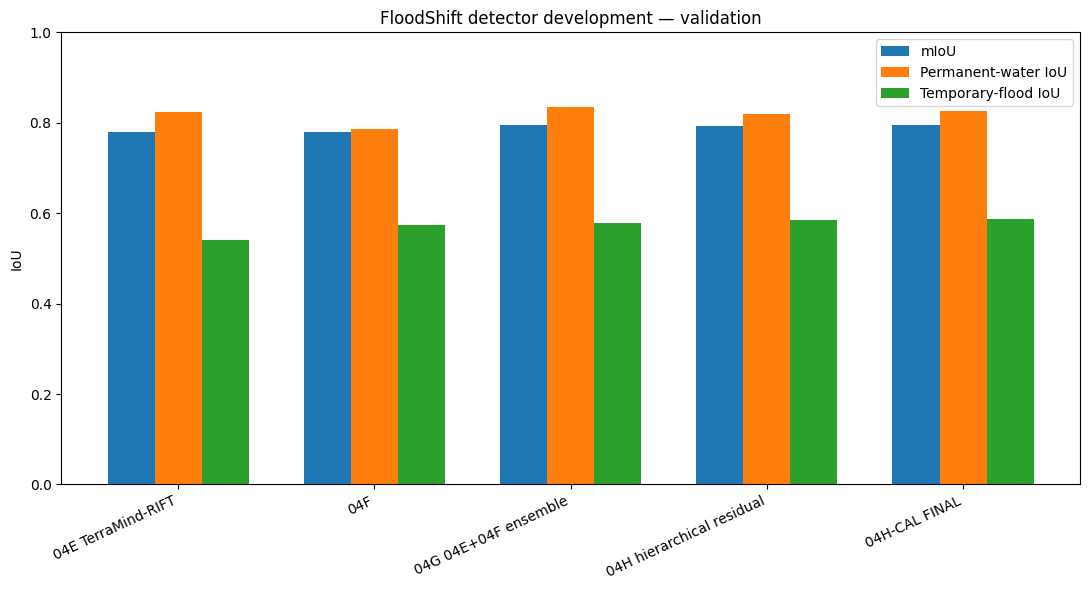

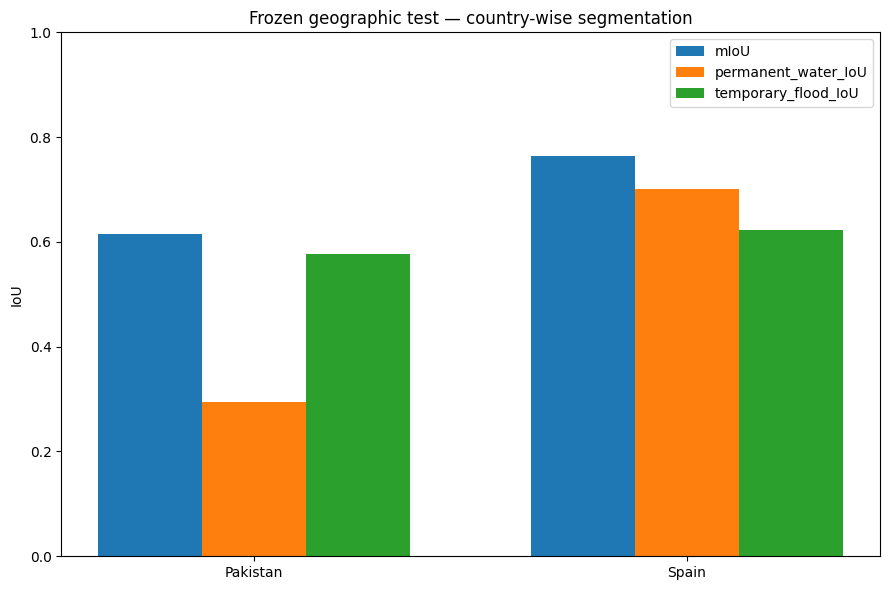

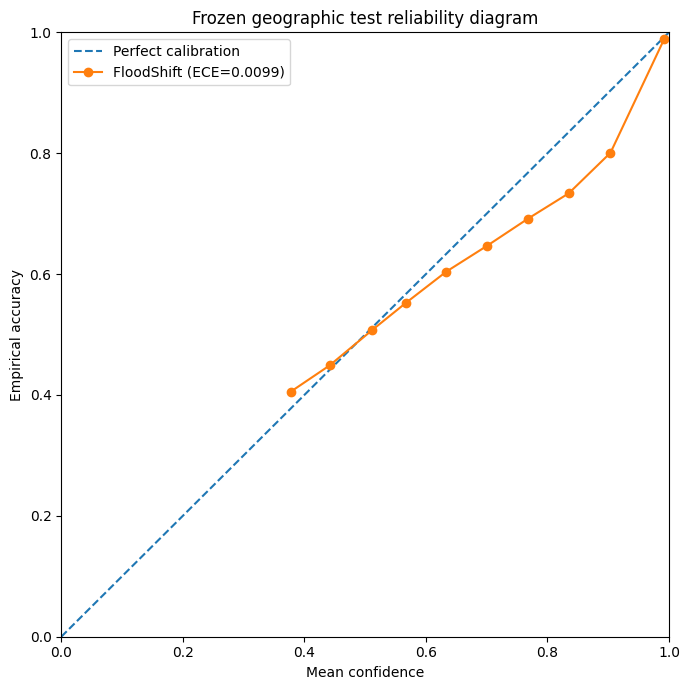

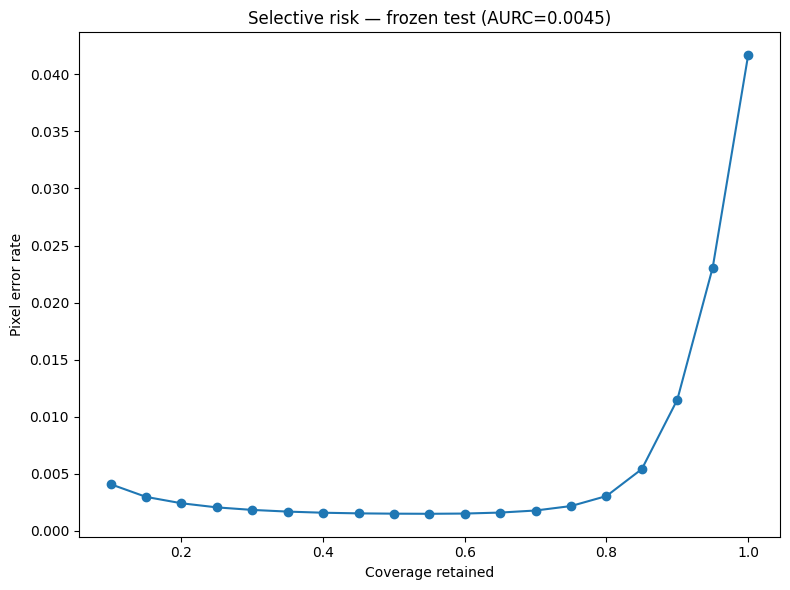

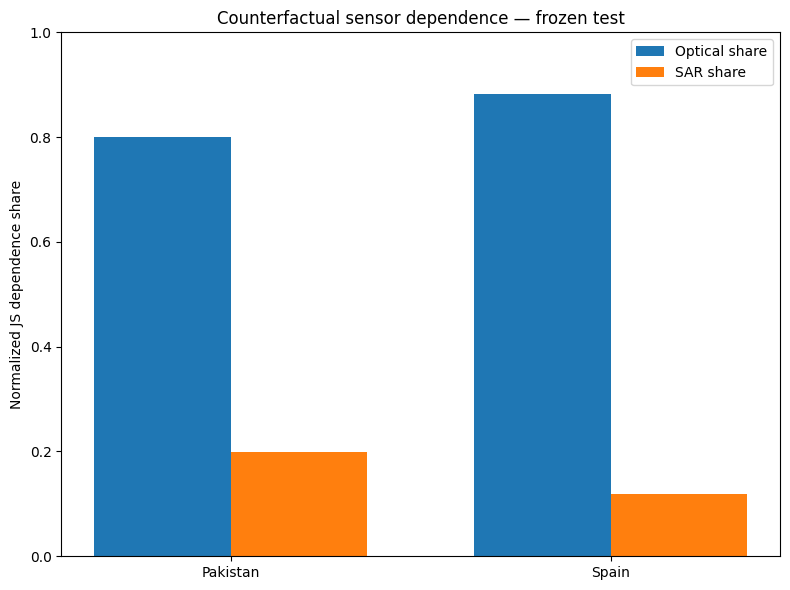

P21-C20 — PAPER FIGURES COMPLETE ✅


In [44]:
# ============================================================
# P21-C20 — PAPER FIGURES
# ============================================================

# Figure 1 — detector development
fig,ax = plt.subplots(figsize=(11,6))
x = np.arange(len(segmentation_ledger))
w = 0.24
ax.bar(x-w,segmentation_ledger["mIoU"],w,label="mIoU")
ax.bar(x,segmentation_ledger["permanent_water_IoU"],w,label="Permanent-water IoU")
ax.bar(x+w,segmentation_ledger["temporary_flood_IoU"],w,label="Temporary-flood IoU")
ax.set_xticks(x)
ax.set_xticklabels(segmentation_ledger["model"],rotation=25,ha="right")
ax.set_ylim(0,1)
ax.set_ylabel("IoU")
ax.set_title("FloodShift detector development — validation")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_ROOT/"Figure_Detector_Development.png",dpi=220,bbox_inches="tight")
plt.show()

# Figure 2 — country test metrics
metrics_cols = ["mIoU","permanent_water_IoU","temporary_flood_IoU"]
x = np.arange(len(country_df))
w = 0.24
fig,ax = plt.subplots(figsize=(9,6))
for j,col in enumerate(metrics_cols):
    ax.bar(x+(j-1)*w,country_df[col],w,label=col)
ax.set_xticks(x)
ax.set_xticklabels(country_df["country"])
ax.set_ylim(0,1)
ax.set_ylabel("IoU")
ax.set_title("Frozen geographic test — country-wise segmentation")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_ROOT/"Figure_Test_Country_Metrics.png",dpi=220,bbox_inches="tight")
plt.show()

# Figure 3 — reliability
plot_df = reliability_df.dropna(subset=["confidence","accuracy"])
fig,ax = plt.subplots(figsize=(7,7))
ax.plot([0,1],[0,1],linestyle="--",label="Perfect calibration")
ax.plot(
    plot_df["confidence"],plot_df["accuracy"],
    marker="o",label=f"FloodShift (ECE={test_ece:.4f})"
)
ax.set_xlabel("Mean confidence")
ax.set_ylabel("Empirical accuracy")
ax.set_xlim(0,1)
ax.set_ylim(0,1)
ax.set_title("Frozen geographic test reliability diagram")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_ROOT/"Figure_Test_Reliability_Diagram.png",dpi=220,bbox_inches="tight")
plt.show()

# Figure 4 — selective risk
fig,ax = plt.subplots(figsize=(8,6))
ax.plot(
    risk_coverage_df["coverage"],
    risk_coverage_df["risk_error_rate"],
    marker="o",
)
ax.set_xlabel("Coverage retained")
ax.set_ylabel("Pixel error rate")
ax.set_title(f"Selective risk — frozen test (AURC={test_aurc:.4f})")
fig.tight_layout()
fig.savefig(FIG_ROOT/"Figure_Test_Risk_Coverage.png",dpi=220,bbox_inches="tight")
plt.show()

# Figure 5 — sensor dependence
sensor_country = (
    test_scene_df.groupby("country",as_index=False)
    .agg(
        optical_share=("optical_share","mean"),
        sar_share=("sar_share","mean"),
        flip_no_optical=("flip_rate_no_optical","mean"),
        flip_no_sar=("flip_rate_no_sar","mean"),
    )
)

x = np.arange(len(sensor_country))
w = 0.36
fig,ax = plt.subplots(figsize=(8,6))
ax.bar(x-w/2,sensor_country["optical_share"],w,label="Optical share")
ax.bar(x+w/2,sensor_country["sar_share"],w,label="SAR share")
ax.set_xticks(x)
ax.set_xticklabels(sensor_country["country"])
ax.set_ylim(0,1)
ax.set_ylabel("Normalized JS dependence share")
ax.set_title("Counterfactual sensor dependence — frozen test")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_ROOT/"Figure_Test_Sensor_Dependence.png",dpi=220,bbox_inches="tight")
plt.show()

sensor_country.to_csv(
    TABLE_ROOT/"FloodShift_11_test_sensor_dependence_by_country.csv",
    index=False,
)

print("P21-C20 — PAPER FIGURES COMPLETE ✅")

In [45]:
# ============================================================
# P21-C21 — FINAL SCIENTIFIC LIMITATIONS + RQ CLOSURE
# ============================================================

limitations = [
    "Counterfactual SAR/optical attribution measures model dependence/sensitivity, not physical causality.",
    "Predictive entropy is calibrated predictive uncertainty, not independently justified Bayesian epistemic uncertainty.",
    "The Gaussian VLP latent variance is supervised/aligned to detector uncertainty; it is not a standalone epistemic posterior.",
    "The accepted detector is strongly optical-dependent and is not claimed to degrade gracefully under complete sensor loss.",
    "05B improved corrupted/missing-modality conditions but was rejected because clean segmentation deteriorated materially.",
    "The VLP reasons over verified evidence representations; it does not replace the raw multisensor detector.",
    "Connected components are pixel-mask structures, not proof of separate hydrological events.",
    "FloodShift maps the satellite observation; it does not forecast future flooding without a separate temporal/hydrological model.",
    "No casualties, personal harm, property damage, road closure, flood depth, or physical cause is inferred without verified external data.",
    "Arbitrary RGB/JPEG imagery is not equivalent to the required Sentinel-1 VV/VH + Sentinel-2 10-band + P(clear) input.",
    "The Pakistan+Spain test is a one-time geographic generalization evaluation; no post-test tuning is permitted.",
]

with open(OUTPUT_ROOT/"FloodShift_11_LIMITATIONS.md","w") as f:
    f.write("# FloodShift — Final Scientific Limitations\n\n")
    for x in limitations:
        f.write(f"- {x}\n")

rq_df = pd.DataFrame([
    ["RQ2","Reliability-aware multimodal fusion","04E→04H-CAL development/ablations","CLOSED"],
    ["RQ3","Corrupt/missing-modality reliability","05 + rejected 05B trade-off","CLOSED_WITH_LIMITATION"],
    ["RQ4","Counterfactual sensor dependence","06 + frozen geographic-test JS/flip analysis","CLOSED_AS_MODEL_DEPENDENCE"],
    ["RQ5","Gaussian/VLP grounding and abstention","09A→09B→10; final VLP accepted","CLOSED"],
    ["RQ6","Geographic generalization and calibration","Frozen Pakistan+Spain test in this notebook","CLOSED"],
],columns=["RQ","question","evidence","status"])

rq_df.to_csv(
    TABLE_ROOT/"FloodShift_11_research_question_closure.csv",
    index=False,
)

display(rq_df)
print("P21-C21 COMPLETE ✅")

,RQ,question,evidence,status
0,RQ2,Reliability-aware multimodal fusion,04E→04H-CAL development/ablations,CLOSED
1,RQ3,Corrupt/missing-modality reliability,05 + rejected 05B trade-off,CLOSED_WITH_LIMITATION
2,RQ4,Counterfactual sensor dependence,06 + frozen geographic-test JS/flip analysis,CLOSED_AS_MODEL_DEPENDENCE
3,RQ5,Gaussian/VLP grounding and abstention,09A→09B→10; final VLP accepted,CLOSED
4,RQ6,Geographic generalization and calibration,Frozen Pakistan+Spain test in this notebook,CLOSED


P21-C21 COMPLETE ✅


In [46]:
# ============================================================
# P21-C22 — FINAL CLOSURE REPORT + REPRODUCIBILITY ARCHIVE
# ============================================================

final_summary = {
    "project":"FloodShift",
    "title":(
        "Reliability-Aware SAR-Optical Flood Segmentation with "
        "Counterfactual Sensor Attribution and a Distribution-Grounded Variational VLM"
    ),
    "final_detector":"04H-CAL",
    "checkpoint_sha256":EXPECTED_04H_SHA,
    "type_logit_bias":TYPE_BIAS,
    "temperature":TEMPERATURE,
    "validation_reproduction":VAL_REPRO,
    "protocol_freeze_sha256":FREEZE_SHA,
    "test_split":"58 scenes: 28 Pakistan + 30 Spain",
    "test_metrics":{
        **{k:float(v) for k,v in test_pooled_metrics.items()},
        "ECE":float(test_ece),
        "entropy_error_AUROC":float(entropy_error_auroc),
        "AURC":float(test_aurc),
        "mean_optical_share":float(test_scene_df["optical_share"].mean()),
        "mean_sar_share":float(test_scene_df["sar_share"].mean()),
    },
    "packet_verifier_failures":int(packet_issue_df["issue_count"].sum()),
    "rendered_numeric_violations":int(report_df["numeric_violation_count"].sum()),
    "post_test_tuning":False,
    "research_status":"FINAL_RESEARCH_PIPELINE_CLOSED",
}

with open(OUTPUT_ROOT/"FloodShift_11_FINAL_CLOSURE_REPORT.json","w") as f:
    json.dump(final_summary,f,indent=2)

with open(OUTPUT_ROOT/"FloodShift_11_FINAL_CLOSURE_REPORT.md","w") as f:
    f.write("# FloodShift — Final Research Closure Report\n\n")
    f.write(f"- mIoU: **{test_pooled_metrics['mIoU']:.4f}**\n")
    f.write(f"- Non-flood IoU: **{test_pooled_metrics['non_flood_IoU']:.4f}**\n")
    f.write(f"- Permanent-water IoU: **{test_pooled_metrics['permanent_water_IoU']:.4f}**\n")
    f.write(f"- Temporary-flood IoU: **{test_pooled_metrics['temporary_flood_IoU']:.4f}**\n")
    f.write(f"- ECE: **{test_ece:.4f}**\n")
    f.write(f"- Entropy-error AUROC: **{entropy_error_auroc:.4f}**\n")
    f.write(f"- AURC: **{test_aurc:.4f}**\n")
    f.write(f"- Packet verifier failures: **{int(packet_issue_df['issue_count'].sum())}**\n")
    f.write(f"- Rendered numeric violations: **{int(report_df['numeric_violation_count'].sum())}**\n")
    f.write("\nNo model or threshold was tuned after opening the test.\n")

# Environment record
with open(OUTPUT_ROOT/"FloodShift_11_environment.json","w") as f:
    json.dump({
        "python":sys.version,
        "numpy":np.__version__,
        "pandas":pd.__version__,
        "torch":torch.__version__,
        "terratorch":getattr(terratorch,"__version__","unknown"),
        "device":str(DEVICE),
        "seed":SEED,
        "protocol_freeze_sha256":FREEZE_SHA,
    },f,indent=2)

def make_manifest(root):
    rows = []
    for p in sorted(root.rglob("*")):
        if p.is_file():
            rows.append({
                "relative_path":str(p.relative_to(root)),
                "bytes":int(p.stat().st_size),
                "sha256":sha256_file(p),
            })
    return pd.DataFrame(rows)

manifest_out = make_manifest(OUTPUT_ROOT)
manifest_out.to_csv(
    OUTPUT_ROOT/"FloodShift_11_file_manifest.csv",
    index=False,
)

ARCHIVE_PATH = Path(
    "/kaggle/working/FloodShift_11_FINAL_RESEARCH_ARCHIVE.zip"
)

with zipfile.ZipFile(
    ARCHIVE_PATH,"w",compression=zipfile.ZIP_DEFLATED
) as zf:
    for p in sorted(OUTPUT_ROOT.rglob("*")):
        if p.is_file():
            zf.write(p,arcname=p.relative_to(OUTPUT_ROOT))

ARCHIVE_SHA = sha256_file(ARCHIVE_PATH)

print("=" * 112)
print("P21-C22 — FINAL RESEARCH CLOSURE")
print("=" * 112)
print(json.dumps(final_summary["test_metrics"],indent=2))
print()
print("Archive:", ARCHIVE_PATH)
print("SHA256 :", ARCHIVE_SHA)
print()
print("FLOODSHIFT NON-DASHBOARD RESEARCH PIPELINE: CLOSED ✅")
print("P21-C22 COMPLETE ✅")

P21-C22 — FINAL RESEARCH CLOSURE
{
  "non_flood_IoU": 0.9699602826574977,
  "non_flood_Dice": 0.9847511050821905,
  "non_flood_Precision": 0.9909123205615221,
  "non_flood_Recall": 0.9786660335878523,
  "permanent_water_IoU": 0.6154250609811185,
  "permanent_water_Dice": 0.7619357602479484,
  "permanent_water_Precision": 0.8906178501669547,
  "permanent_water_Recall": 0.6657447548757081,
  "temporary_flood_IoU": 0.6076267813190892,
  "temporary_flood_Dice": 0.7559301554064926,
  "temporary_flood_Precision": 0.6709485987077658,
  "temporary_flood_Recall": 0.8655611017848098,
  "mIoU": 0.7310040416525685,
  "macro_Dice": 0.8342056735788773,
  "ECE": 0.009931645807712625,
  "entropy_error_AUROC": 0.9350487778519514,
  "AURC": 0.00449634878609477,
  "mean_optical_share": 0.8425829593211881,
  "mean_sar_share": 0.157417040678812
}

Archive: /kaggle/working/FloodShift_11_FINAL_RESEARCH_ARCHIVE.zip
SHA256 : a5e6fdd1c4765b63df2e35d5b4e6141bb5444f61ee9e3a6d9c6d2fa6451b2f37

FLOODSHIFT NON-DASHB

# Done

When the last cell prints:

```text
FLOODSHIFT NON-DASHBOARD RESEARCH PIPELINE: CLOSED ✅
```

the research pipeline is closed.

Keep `/kaggle/working/FloodShift_11_FINAL_RESEARCH_ARCHIVE.zip`.

Anything after this is deployment/dashboard engineering and paper prose polishing—not model development.